## 1. Dataset upload and extraction






In [1]:
from google.colab import files
uploaded = files.upload()

Saving deep-pharma-multimodal-intelligence-challenge-data-hack-3-0.zip to deep-pharma-multimodal-intelligence-challenge-data-hack-3-0.zip


In [2]:
import shutil
import zipfile
from pathlib import Path

REQUIRED_FILES = ("train.csv", "test.csv", "sample_submission.csv")
EXTRACT_DIR = Path("working_data")

def find_dataset_files(directory):
    paths = {name: Path(directory) / name for name in REQUIRED_FILES}
    return paths if all(path.is_file() for path in paths.values()) else None


def extract_required_files(zip_path, extract_dir):
    extract_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:
        members = {Path(info.filename).name: info for info in archive.infolist() if not info.is_dir()}
        missing = [name for name in REQUIRED_FILES if name not in members]
        if missing:
            print(f"{zip_path} does not contain: {missing}")
            return None
        for name in REQUIRED_FILES:
            target = extract_dir / name
            if target.is_file() and target.stat().st_size == members[name].file_size:
                continue
            with archive.open(members[name]) as source, open(target, "wb") as destination:
                shutil.copyfileobj(source, destination)
    return find_dataset_files(extract_dir)


uploaded_names = list(uploaded.keys())
del uploaded

zip_names = [name for name in uploaded_names if name.lower().endswith(".zip")]
if not zip_names:
    raise ValueError("No ZIP file was uploaded. Run the upload cell again and select the dataset ZIP.")

dataset_paths = None
for zip_name in zip_names:
    try:
        dataset_paths = extract_required_files(Path(zip_name), EXTRACT_DIR)
    except zipfile.BadZipFile:
        print(f"{zip_name} is not a valid ZIP archive")
        continue
    if dataset_paths:
        print(f"Using {zip_name}; the three CSV files were extracted to {EXTRACT_DIR.resolve()}")
        break

if dataset_paths is None:
    raise ValueError("None of the uploaded ZIP files contained train.csv, test.csv and sample_submission.csv")

for name, path in dataset_paths.items():
    print(f"{name}: {path.stat().st_size / 1e6:.1f} MB")

Using deep-pharma-multimodal-intelligence-challenge-data-hack-3-0.zip; the three CSV files were extracted to /content/working_data
train.csv: 173.5 MB
test.csv: 43.0 MB
sample_submission.csv: 1.3 MB


## 2. Import libraries and configure reproducibility


In [3]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("rdkit") is None:
    result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rdkit"], capture_output=True, text=True)
    print("RDKit installed" if result.returncode == 0 else "RDKit could not be installed; fingerprints will be skipped")
else:
    print("RDKit is already available")

RDKit installed


In [4]:
import html
import json
import random
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

SEVERITY_ORDER = ["Minor", "Moderate", "Major"]
TEXT_MIN_MEAN_LENGTH = 40
DRUG_SUFFIXES = ("A", "B")
INLINE_TAG_PATTERN = re.compile(r"</?(?:sub|sup|i|b|em|strong|u)\s*/?>", re.IGNORECASE)
ANY_TAG_PATTERN = re.compile(r"</?[A-Za-z][^<>]*>")
CITATION_TOKEN = r"(?:[A-Z]\d{1,8}|FDA [Ll]abel|Label|MSDS)"
CITATION_PATTERN = re.compile(r"\s*\[" + CITATION_TOKEN + r"(?:\s*,\s*" + CITATION_TOKEN + r")*\]")
WHITESPACE_PATTERN = re.compile(r"\s+")
SMILES_ALLOWED_PATTERN = re.compile(r"^[A-Za-z0-9@+\-\[\]\(\)=#$%/\\.:*]+$")
TFIDF_TOKEN_PATTERN = r"(?u)\b\w[\w\-/+]*\b"

In [5]:
CONFIG = {
    "validation_fraction": 0.2,
    "max_features": 50000,
    "min_df": None,
    "ngram_max": 2,
    "fingerprint_bits": 2048,
}

OUTPUT_DIR = Path("outputs")
folders = {name: OUTPUT_DIR / name for name in ("eda", "processed", "features", "splits", "metadata", "models")}
for folder in folders.values():
    folder.mkdir(parents=True, exist_ok=True)

def print_section(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


def json_default(obj):
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    raise TypeError(f"Cannot serialise {type(obj)}")


def save_json(payload, path):
    with open(path, "w", encoding="utf-8") as file:
        json.dump(payload, file, indent=2, default=json_default, ensure_ascii=False)


def short_label(column):
    if column.startswith("Target_") and column.count("_") >= 2:
        return column.split("_", 2)[2]
    return column


def save_figure(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


print(f"Seed: {SEED}")
print("Output folders:", [str(folder) for folder in folders.values()])

Seed: 42
Output folders: ['outputs/eda', 'outputs/processed', 'outputs/features', 'outputs/splits', 'outputs/metadata', 'outputs/models']


## 3. Load and inspect the dataset


In [6]:
def read_csv_file(path):
    try:
        return pd.read_csv(path)
    except (pd.errors.ParserError, pd.errors.EmptyDataError, UnicodeDecodeError) as error:
        raise ValueError(f"Could not parse {path.name}: {error}") from error


train, test, sample = (read_csv_file(dataset_paths[name]) for name in REQUIRED_FILES)

In [7]:
def show_overview(train, test, sample):
    print(f"train: {train.shape}, test: {test.shape}, sample_submission: {sample.shape}")
    print(f"Memory used by train: {train.memory_usage(deep=True).sum() / 1e6:.0f} MB, test: {test.memory_usage(deep=True).sum() / 1e6:.0f} MB")
    print("Column dtypes in train:", train.dtypes.astype(str).value_counts().to_dict())
    print("\nPreview of train (first 3 rows, first 5 columns, long values shortened for display):")
    preview = train.iloc[:3, :5].copy()
    for col in preview.columns:
        preview[col] = preview[col].astype(str).str.slice(0, 28).str.replace(r"\s+", " ", regex=True)
    print(preview.to_string())


show_overview(train, test, sample)

train: (15284, 126), test: (3974, 25), sample_submission: (3974, 102)
Memory used by train: 229 MB, test: 56 MB
Column dtypes in train: {'float64': 100, 'object': 26}

Preview of train (first 3 rows, first 5 columns, long values shortened for display):
        Pair_ID                      SMILES_A                      SMILES_B                   Mechanism_A            Pharmacodynamics_A
0  Train_000000  COc1cc2c3cc1Oc1cc(ccc1O)CC1c  CC(C)CCCCC(=O)N[C@@H](CCN)C(  The alpha and gamma diaminob  Polymyxin B is an antibiotic
1  Train_000001  O=c1oc2ccccc2c(O)c1Cc1c(O)c2  CC(C)(Oc1ccc(C(=O)c2ccc(Cl)c  Having performed clinical st  Various clinical studies hav
2  Train_000002  Cc1nc2c([nH]1)CCN(C(=O)c1ccc  COc1c(OCCCN2CCOCC2)ccc2c3n(c  Follicular lymphoma is a B-c  Copanlisib has demonstrated 


In [8]:
def validate_schema(train, test, sample):
    id_col = sample.columns[0]
    target_cols = [c for c in sample.columns if c != id_col]
    problems = []

    for name, frame in (("train", train), ("test", test)):
        if id_col not in frame.columns:
            problems.append(f"ID column '{id_col}' is missing from {name}.csv")
    if problems:
        raise ValueError("\n".join(problems))

    missing_targets = [c for c in target_cols if c not in train.columns]
    if missing_targets:
        problems.append(f"{len(missing_targets)} sample_submission columns are absent from train.csv, e.g. {missing_targets[:3]}")
    targets_in_test = [c for c in target_cols if c in test.columns]
    if targets_in_test:
        problems.append(f"{len(targets_in_test)} target columns also appear in test.csv, which would be leakage")
    unknown_test_cols = [c for c in test.columns if c not in train.columns]
    if unknown_test_cols:
        problems.append(f"test.csv has columns that train.csv lacks: {unknown_test_cols[:5]}")
    if set(test[id_col]) != set(sample[id_col]):
        problems.append("Pair_ID values in test.csv and sample_submission.csv do not match")
    if train[id_col].duplicated().any() or test[id_col].duplicated().any():
        problems.append("Duplicate identifiers found in train.csv or test.csv")

    shared = [c for c in test.columns if c in train.columns]
    kind_mismatch = [
        c for c in shared if pd.api.types.is_numeric_dtype(train[c]) != pd.api.types.is_numeric_dtype(test[c])
    ]
    if kind_mismatch:
        problems.append(f"Numeric versus text dtype mismatch between train and test: {kind_mismatch}")

    if problems:
        raise ValueError("Schema validation failed:\n- " + "\n- ".join(problems))

    order_matches = bool((test[id_col].values == sample[id_col].values).all())
    print(f"Schema check passed: id column '{id_col}', {len(target_cols)} targets in sample_submission.")
    print(f"Test and sample_submission rows are in the same order: {order_matches}")
    extra_train_cols = [c for c in train.columns if c not in test.columns and c not in target_cols]
    print(f"Train-only columns that are not submission targets: {extra_train_cols if extra_train_cols else 'none'}")
    return id_col, target_cols


def identify_columns(train, test, id_col, target_cols):
    feature_cols = [c for c in test.columns if c != id_col]
    smiles_cols = [c for c in feature_cols if "smiles" in c.lower()]
    text_cols, category_cols, numeric_cols = [], [], []
    for col in feature_cols:
        if col in smiles_cols:
            continue
        if pd.api.types.is_numeric_dtype(train[col]):
            numeric_cols.append(col)
            continue
        lengths = train[col].dropna().astype(str).str.len()
        if not lengths.empty and lengths.mean() >= TEXT_MIN_MEAN_LENGTH:
            text_cols.append(col)
        else:
            category_cols.append(col)
    if not text_cols:
        raise ValueError("No natural-language text columns were detected in the feature set")

    binary_cols, regression_cols, label_cols = [], [], []
    for col in target_cols:
        series = train[col]
        if not pd.api.types.is_numeric_dtype(series):
            label_cols.append(col)
        elif set(series.dropna().unique()) <= {0, 1}:
            binary_cols.append(col)
        else:
            regression_cols.append(col)

    paired = {}
    for col in smiles_cols + text_cols + category_cols + numeric_cols:
        match = re.match(r"^(.*)_([AB])$", col)
        if match:
            paired.setdefault(match.group(1), {})[match.group(2)] = col
    paired = {base: sides for base, sides in paired.items() if set(sides) == set(DRUG_SUFFIXES)}

    return {
        "id_col": id_col,
        "feature_cols": feature_cols,
        "smiles_cols": smiles_cols,
        "text_cols": text_cols,
        "category_cols": category_cols,
        "numeric_cols": numeric_cols,
        "target_cols": target_cols,
        "binary_target_cols": binary_cols,
        "regression_target_cols": regression_cols,
        "severity_col": label_cols[0] if label_cols else None,
        "paired_fields": paired,
    }


def print_schema(schema):
    print(f"Identifier: {schema['id_col']}")
    print(f"Molecular structure columns: {schema['smiles_cols']}")
    print(f"Natural-language text columns ({len(schema['text_cols'])}): {schema['text_cols']}")
    print(f"Categorical list columns: {schema['category_cols']}")
    print(f"Native numeric feature columns: {schema['numeric_cols'] if schema['numeric_cols'] else 'none'}")
    print(f"Single-label target: {schema['severity_col']}")
    print(f"Binary targets: {len(schema['binary_target_cols'])}, continuous targets: {len(schema['regression_target_cols'])}")
    print(f"Fields available for both drug A and drug B: {len(schema['paired_fields'])}")


def downcast_binary_targets(train, binary_cols):
    if binary_cols and not train[binary_cols].isna().any().any():
        train[binary_cols] = train[binary_cols].astype("int8")
    return train


id_col, target_cols = validate_schema(train, test, sample)
schema = identify_columns(train, test, id_col, target_cols)
train = downcast_binary_targets(train, schema["binary_target_cols"])
print()
print_schema(schema)

train_only = [c for c in train.columns if c not in test.columns]
test_only = [c for c in test.columns if c not in train.columns]
print()
print(f"Columns only in train: {len(train_only)} (exactly the submission targets: {set(train_only) == set(schema['target_cols'])})")
print(f"Columns only in test: {test_only if test_only else 'none'}")
column_overview = pd.DataFrame({"dtype": train[schema["feature_cols"]].dtypes.astype(str), "missing": train[schema["feature_cols"]].isna().sum()})
display(column_overview)

Schema check passed: id column 'Pair_ID', 101 targets in sample_submission.
Test and sample_submission rows are in the same order: True
Train-only columns that are not submission targets: none

Identifier: Pair_ID
Molecular structure columns: ['SMILES_A', 'SMILES_B']
Natural-language text columns (20): ['Mechanism_A', 'Mechanism_B', 'Metabolism_A', 'Metabolism_B', 'Pharmacodynamics_A', 'Pharmacodynamics_B', 'Absorption_A', 'Absorption_B', 'Half_Life_A', 'Half_Life_B', 'Protein_Binding_A', 'Protein_Binding_B', 'Elimination_Route_A', 'Elimination_Route_B', 'Indication_A', 'Indication_B', 'Warning_A', 'Warning_B', 'Toxicity_A', 'Toxicity_B']
Categorical list columns: ['CYP450_Enzymes_A', 'CYP450_Enzymes_B']
Native numeric feature columns: none
Single-label target: Severity
Binary targets: 50, continuous targets: 50
Fields available for both drug A and drug B: 12

Columns only in train: 101 (exactly the submission targets: True)
Columns only in test: none


,dtype,missing
SMILES_A,object,0
SMILES_B,object,0
Mechanism_A,object,0
Mechanism_B,object,0
Metabolism_A,object,0
Metabolism_B,object,0
Pharmacodynamics_A,object,0
Pharmacodynamics_B,object,0
Absorption_A,object,0
Absorption_B,object,0


## 4. Data quality checks



Feature columns with missing values: 6
                  train_missing  train_pct  test_missing  test_pct
column                                                            
Indication_A               2922       19.1           779      19.6
Warning_A                  4737       31.0          1232      31.0
CYP450_Enzymes_A           9089       59.5          2500      62.9
Indication_B               1730       11.3           421      10.6
Warning_B                  1730       11.3           421      10.6
CYP450_Enzymes_B           7193       47.1          1886      47.5
Missing values across all target columns in train: 0

Duplicate analysis
  fully duplicated train rows: 0
  train rows with duplicated feature values: 0
  duplicated Pair_ID in train/test: 0/0
  Pair_ID shared between train and test: 0
  train rows repeating an ordered SMILES pair: 468


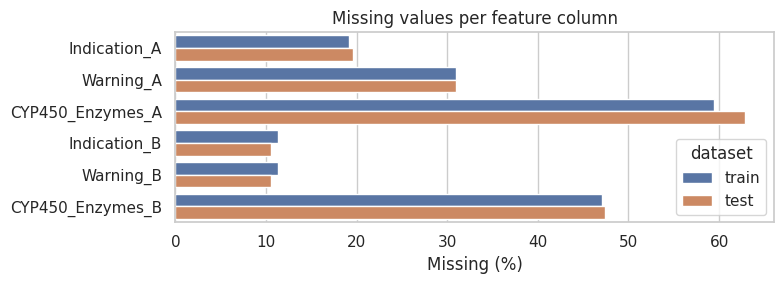

In [9]:
def run_quality_checks(train, test, schema, eda_dir):
    id_col = schema["id_col"]
    missing = pd.DataFrame(
        {
            "train_missing": train.isna().sum(),
            "train_pct": train.isna().mean() * 100,
            "test_missing": test.reindex(columns=train.columns).isna().sum(),
            "test_pct": test.reindex(columns=train.columns).isna().mean() * 100,
        }
    )
    missing = missing[(missing.train_missing > 0) | (missing.test_missing > 0)]
    missing = missing[~missing.index.isin(schema["target_cols"])]
    missing.index.name = "column"
    missing.to_csv(eda_dir / "missing_values.csv")
    print(f"\nFeature columns with missing values: {len(missing)}")
    if len(missing):
        print(missing.round(1).to_string())
    target_missing = int(train[schema["target_cols"]].isna().sum().sum())
    print(f"Missing values across all target columns in train: {target_missing}")

    feature_cols = schema["feature_cols"]
    ordered_pairs = train.duplicated(schema["smiles_cols"]).sum() if len(schema["smiles_cols"]) == 2 else 0
    print("\nDuplicate analysis")
    print(f"  fully duplicated train rows: {int(train.duplicated().sum())}")
    print(f"  train rows with duplicated feature values: {int(train.duplicated(feature_cols).sum())}")
    print(f"  duplicated {id_col} in train/test: {int(train[id_col].duplicated().sum())}/{int(test[id_col].duplicated().sum())}")
    print(f"  {id_col} shared between train and test: {len(set(train[id_col]) & set(test[id_col]))}")
    print(f"  train rows repeating an ordered SMILES pair: {int(ordered_pairs)}")

    numeric_stats = train.select_dtypes(include="number").describe().T
    numeric_stats.to_csv(eda_dir / "numeric_descriptive_statistics.csv")

    if missing.shape[0]:
        melted = missing.reset_index().melt(id_vars="column", value_vars=["train_pct", "test_pct"], var_name="dataset", value_name="missing_pct")
        melted["dataset"] = melted["dataset"].str.replace("_pct", "", regex=False)
        fig, ax = plt.subplots(figsize=(8, max(3, 0.45 * len(missing))))
        sns.barplot(data=melted, y="column", x="missing_pct", hue="dataset", ax=ax)
        ax.set_title("Missing values per feature column")
        ax.set_xlabel("Missing (%)")
        ax.set_ylabel("")
        save_figure(fig, eda_dir / "missing_values.png")


run_quality_checks(train, test, schema, folders["eda"])

## 5. Exploratory data analysis


Severity class counts: {'Minor': 630, 'Moderate': 10568, 'Major': 4086}
Severity class shares: {'Minor': 0.041, 'Moderate': 0.691, 'Major': 0.267}
Imbalance ratio (largest/smallest class): 16.8
Missing Severity labels: 0
Inconsistent spelling or casing in Severity: False


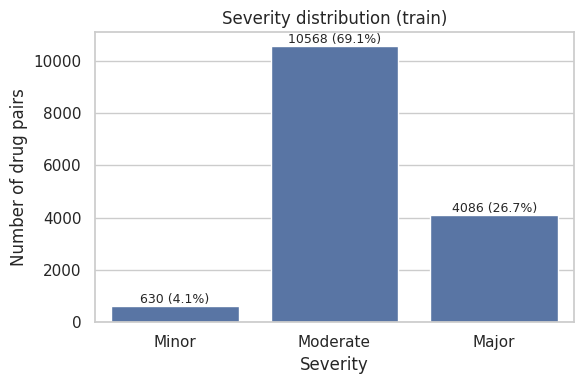

In [10]:
def ordered_classes(values):
    values = list(values)
    known = [c for c in SEVERITY_ORDER if c in values]
    others = sorted(set(values) - set(known))
    return known + others


def analyze_severity(train, schema, eda_dir):
    col = schema["severity_col"]
    if col is None:
        print("No single-label target found; severity analysis skipped.")
        return
    counts = train[col].value_counts(dropna=False)
    counts = counts.reindex(ordered_classes(counts.index.dropna())).dropna().astype(int)
    total = int(counts.sum())
    print(f"{col} class counts: {counts.to_dict()}")
    print(f"{col} class shares: { {k: round(v / total, 3) for k, v in counts.items()} }")
    print(f"Imbalance ratio (largest/smallest class): {counts.max() / counts.min():.1f}")
    print(f"Missing {col} labels: {int(train[col].isna().sum())}")
    raw_unique = train[col].dropna().nunique()
    normalised_unique = train[col].dropna().astype(str).str.strip().str.casefold().nunique()
    print(f"Inconsistent spelling or casing in {col}: {raw_unique != normalised_unique}")

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.barplot(x=list(counts.index), y=counts.values, color="#4C72B0", ax=ax)
    for position, value in enumerate(counts.values):
        ax.text(position, value, f"{value} ({value / total:.1%})", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{col} distribution (train)")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of drug pairs")
    save_figure(fig, eda_dir / "severity_distribution.png")


analyze_severity(train, schema, folders["eda"])

Binary targets: 50; values present: [0, 1]
Per-label prevalence: min 0.182, median 0.214, max 0.274
Pairs with no positive label at all: 68.5%; pairs positive for every label: 6.4%
Mean positive labels per pair: 10.8 (median 0)
Labels are strongly co-occurring rather than independent, so a derived 'any adverse event' target and label-correlation-aware models are worth trying.


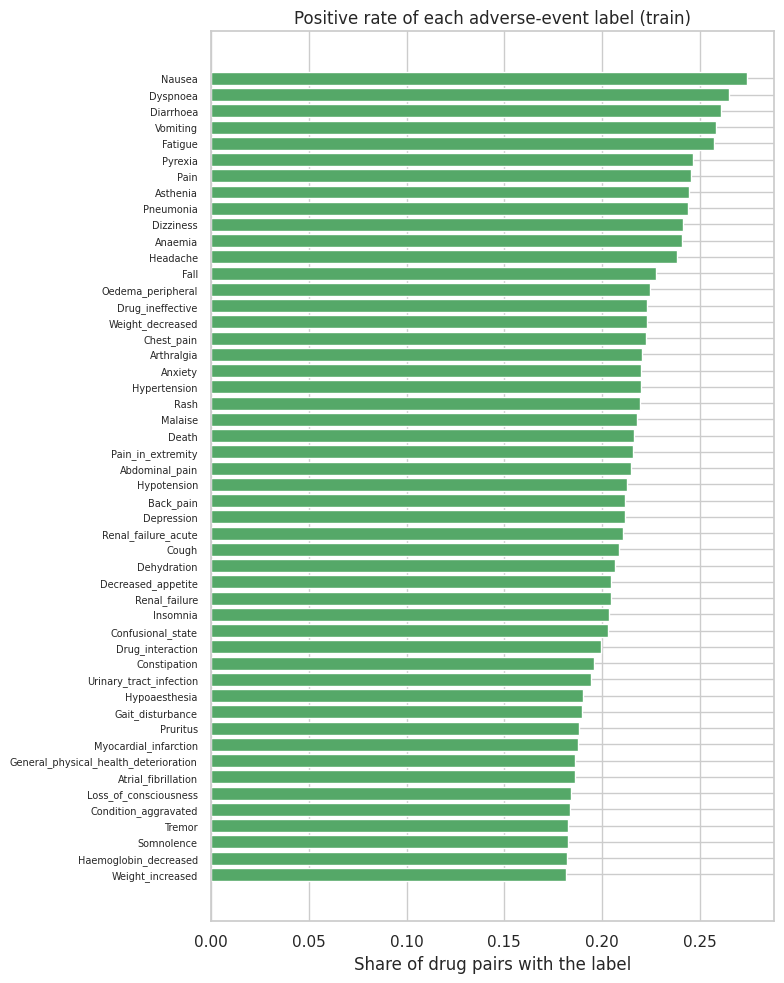

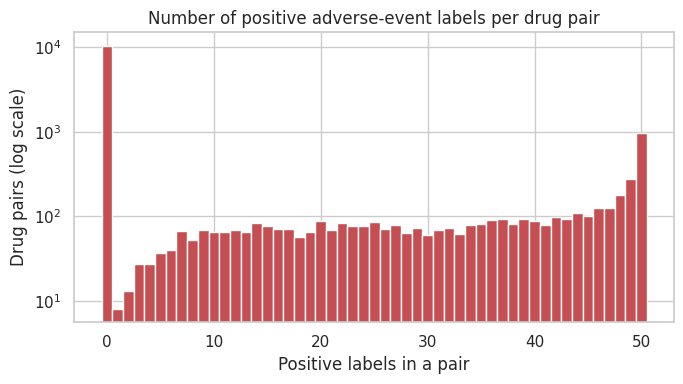

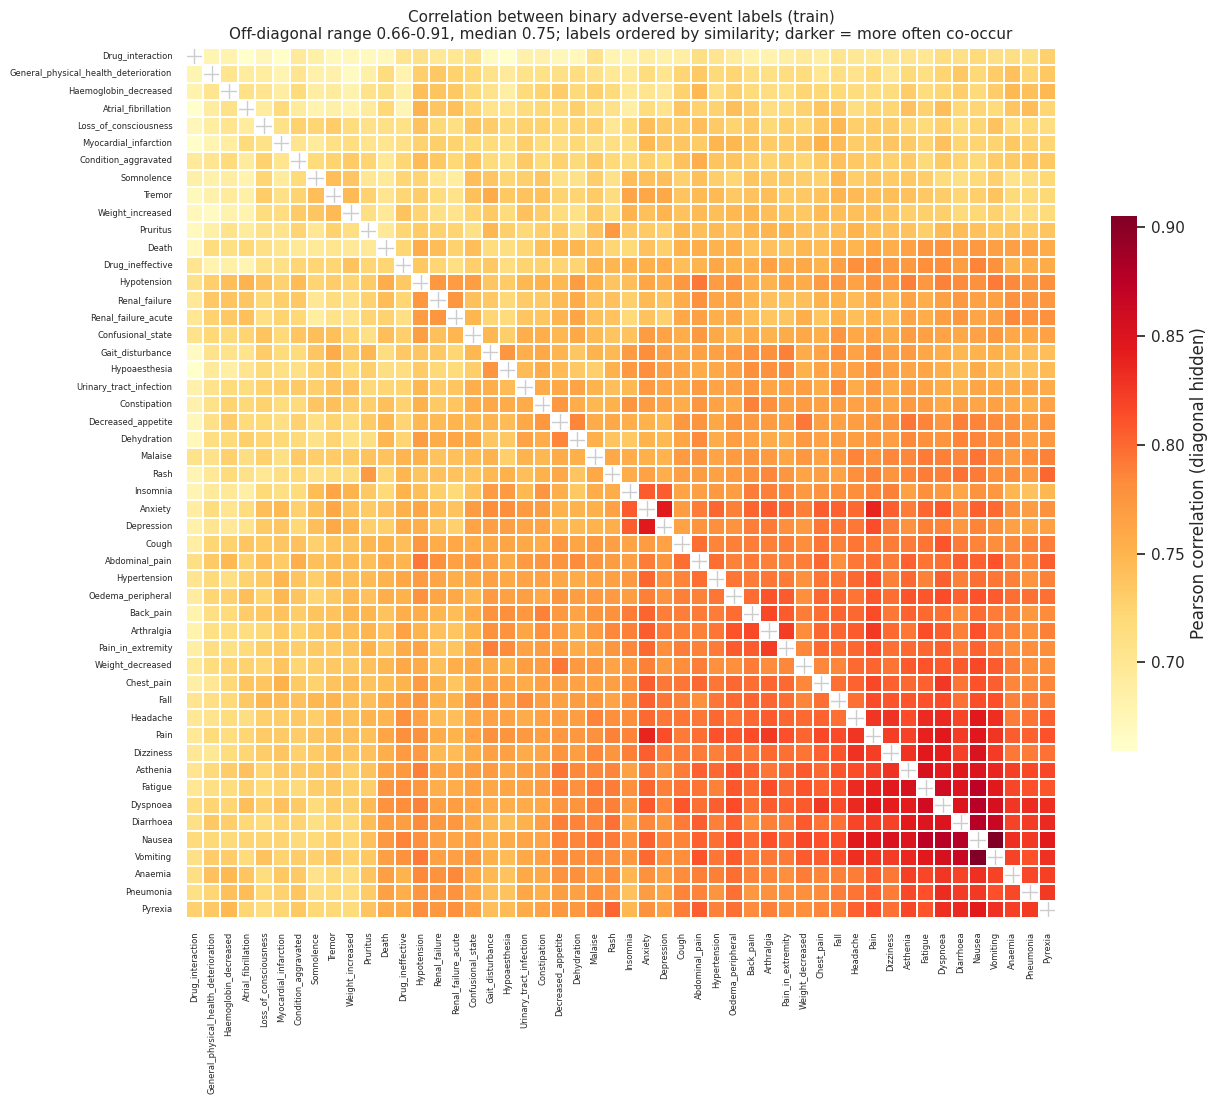

Pairwise label correlation: median 0.75, min 0.66, max 0.91


In [11]:
def analyze_binary_targets(train, schema, eda_dir):
    from scipy.cluster.hierarchy import linkage, leaves_list
    from scipy.spatial.distance import squareform

    cols = schema["binary_target_cols"]
    if not cols:
        print("No binary targets found.")
        return
    labels = train[cols]
    positives = labels.sum()
    summary = pd.DataFrame(
        {
            "label": [short_label(c) for c in cols],
            "column": cols,
            "positives": positives.values.astype(int),
            "prevalence": labels.mean().values,
            "negative_to_positive_ratio": ((len(labels) - positives) / positives.replace(0, np.nan)).values,
        }
    ).sort_values("prevalence")
    summary.to_csv(eda_dir / "binary_target_summary.csv", index=False)

    per_row = labels.sum(axis=1)
    all_zero = float((per_row == 0).mean())
    all_positive = float((per_row == len(cols)).mean())
    print(f"Binary targets: {len(cols)}; values present: {sorted(pd.unique(labels.to_numpy().ravel()).tolist())}")
    print(f"Per-label prevalence: min {summary.prevalence.min():.3f}, median {summary.prevalence.median():.3f}, max {summary.prevalence.max():.3f}")
    print(f"Pairs with no positive label at all: {all_zero:.1%}; pairs positive for every label: {all_positive:.1%}")
    print(f"Mean positive labels per pair: {per_row.mean():.1f} (median {per_row.median():.0f})")
    print("Labels are strongly co-occurring rather than independent, so a derived 'any adverse event' target and label-correlation-aware models are worth trying.")

    fig, ax = plt.subplots(figsize=(8, 10))
    ax.barh(summary.label, summary.prevalence, color="#55A868")
    ax.set_title("Positive rate of each adverse-event label (train)")
    ax.set_xlabel("Share of drug pairs with the label")
    ax.tick_params(axis="y", labelsize=7)
    save_figure(fig, eda_dir / "binary_label_prevalence.png")

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(per_row, bins=np.arange(0, len(cols) + 2) - 0.5, color="#C44E52")
    ax.set_yscale("log")
    ax.set_title("Number of positive adverse-event labels per drug pair")
    ax.set_xlabel("Positive labels in a pair")
    ax.set_ylabel("Drug pairs (log scale)")
    save_figure(fig, eda_dir / "labels_per_pair.png")

    # --- Correlation heatmap (clearer version) ---
    correlation = labels.corr()
    correlation.index = [short_label(c) for c in correlation.index]
    correlation.columns = correlation.index

    off_diagonal = correlation.where(~np.eye(len(correlation), dtype=bool)).stack()
    corr_min, corr_med, corr_max = off_diagonal.min(), off_diagonal.median(), off_diagonal.max()

    # Reorder labels so similar labels sit next to each other
    distance = (1 - correlation.fillna(0).to_numpy())
    distance = (distance + distance.T) / 2
    np.fill_diagonal(distance, 0)
    order = leaves_list(linkage(squareform(distance, checks=False), method="average"))
    correlation = correlation.iloc[order, order]

    # Hide the diagonal (always 1.0) so it doesn't distort the color scale
    mask = np.eye(len(correlation), dtype=bool)

    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(
        correlation,
        mask=mask,
        cmap="YlOrRd",          # light = weaker correlation, dark = stronger
        vmin=corr_min,
        vmax=corr_max,
        square=True,
        linewidths=0.2,
        linecolor="white",
        xticklabels=True,
        yticklabels=True,
        cbar_kws={"shrink": 0.6, "label": "Pearson correlation (diagonal hidden)"},
        ax=ax,
    )
    ax.set_title(
        "Correlation between binary adverse-event labels (train)\n"
        f"Off-diagonal range {corr_min:.2f}-{corr_max:.2f}, median {corr_med:.2f}; "
        "labels ordered by similarity; darker = more often co-occur",
        fontsize=11,
    )
    ax.tick_params(labelsize=6)
    save_figure(fig, eda_dir / "binary_label_correlation.png")
    print(f"Pairwise label correlation: median {corr_med:.2f}, min {corr_min:.2f}, max {corr_max:.2f}")


analyze_binary_targets(train, schema, folders["eda"])

Continuous targets: 50; missing: 0; infinite: 0; negative: 0
Share of exact zeros across all PRR cells: 78.5%
Overall range: 0 to 240
Skewness over all rows per target: median 7.3, range 3.7 to 19.0
Skewness over positive values only: median 4.7
Positive-value outliers (above Q3 + 3*IQR) per target: median 87; nothing was removed or transformed
PRR is positive exactly when the matching binary label is 1 for all of them (50 matched pairs).
Regression targets are therefore zero-inflated and tied to the binary labels; a plain regressor on every row mixes a classification problem with a magnitude problem. Consider a two-stage setup and evaluate on positive rows too.


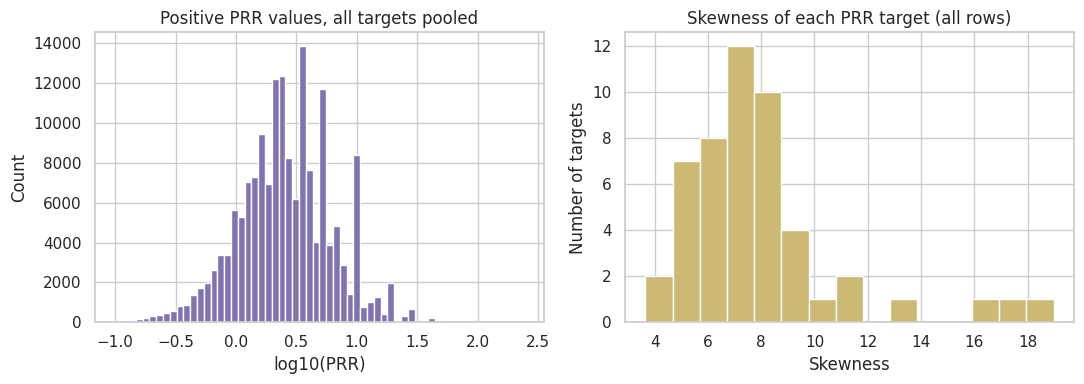

In [12]:
def check_prr_alignment(train, schema):
    binary_by_name = {short_label(c): c for c in schema["binary_target_cols"]}
    matched, broken = 0, 0
    for col in schema["regression_target_cols"]:
        partner = binary_by_name.get(short_label(col))
        if partner is None:
            continue
        matched += 1
        if not ((train[col] > 0) == (train[partner] == 1)).all():
            broken += 1
    return matched, broken


def summarize_regression_targets(train, schema):
    rows = []
    for col in schema["regression_target_cols"]:
        values = train[col]
        positives = values[values > 0]
        q1, q3 = positives.quantile(0.25), positives.quantile(0.75)
        upper_fence = q3 + 3 * (q3 - q1)
        rows.append(
            {
                "column": col,
                "missing": int(values.isna().sum()),
                "min": values.min(),
                "median": values.median(),
                "mean": values.mean(),
                "max": values.max(),
                "zero_fraction": float((values == 0).mean()),
                "negative_values": int((values < 0).sum()),
                "skew_all_rows": values.skew(),
                "positive_count": int(len(positives)),
                "positive_median": positives.median(),
                "positive_p99": positives.quantile(0.99),
                "positive_skew": positives.skew(),
                "positive_outliers_above_q3_plus_3iqr": int((positives > upper_fence).sum()),
            }
        )
    return pd.DataFrame(rows)


def analyze_regression_targets(train, schema, eda_dir):
    cols = schema["regression_target_cols"]
    if not cols:
        print("No continuous targets found.")
        return
    summary = summarize_regression_targets(train, schema)
    summary.to_csv(eda_dir / "regression_target_summary.csv", index=False)
    values = train[cols].to_numpy(dtype=float)
    print(f"Continuous targets: {len(cols)}; missing: {int(np.isnan(values).sum())}; infinite: {int(np.isinf(values).sum())}; negative: {int((values < 0).sum())}")
    print(f"Share of exact zeros across all PRR cells: {(values == 0).mean():.1%}")
    print(f"Overall range: {np.nanmin(values):.3g} to {np.nanmax(values):.3g}")
    print(f"Skewness over all rows per target: median {summary.skew_all_rows.median():.1f}, range {summary.skew_all_rows.min():.1f} to {summary.skew_all_rows.max():.1f}")
    print(f"Skewness over positive values only: median {summary.positive_skew.median():.1f}")
    print(f"Positive-value outliers (above Q3 + 3*IQR) per target: median {int(summary.positive_outliers_above_q3_plus_3iqr.median())}; nothing was removed or transformed")
    matched, broken = check_prr_alignment(train, schema)
    if matched:
        verdict = "all of them" if broken == 0 else f"{matched - broken} of them"
        print(f"PRR is positive exactly when the matching binary label is 1 for {verdict} ({matched} matched pairs).")
        if broken == 0:
            print("Regression targets are therefore zero-inflated and tied to the binary labels; a plain regressor on every row mixes a classification problem with a magnitude problem. Consider a two-stage setup and evaluate on positive rows too.")

    positive_values = values[values > 0]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].hist(np.log10(positive_values), bins=60, color="#8172B2")
    axes[0].set_title("Positive PRR values, all targets pooled")
    axes[0].set_xlabel("log10(PRR)")
    axes[0].set_ylabel("Count")
    axes[1].hist(summary.skew_all_rows, bins=15, color="#CCB974")
    axes[1].set_title("Skewness of each PRR target (all rows)")
    axes[1].set_xlabel("Skewness")
    axes[1].set_ylabel("Number of targets")
    save_figure(fig, eda_dir / "prr_distribution.png")


analyze_regression_targets(train, schema, folders["eda"])

Text fields analysed: 20; categorical list fields: 2
Median characters per text field (train):
column
Mechanism_A            792
Mechanism_B            833
Metabolism_A           407
Metabolism_B           418
Pharmacodynamics_A     725
Pharmacodynamics_B     674
Absorption_A           432
Absorption_B           417
Half_Life_A            111
Half_Life_B            107
Protein_Binding_A       99
Protein_Binding_B       96
Elimination_Route_A    221
Elimination_Route_B    224
Indication_A           287
Indication_B           398
Warning_A              446
Warning_B              533
Toxicity_A             515
Toxicity_B             494
Blank or whitespace-only values (train): 21 in ['Warning_A']
Values containing HTML tags (train): 31965; values containing reference markers such as [A123]: 196461


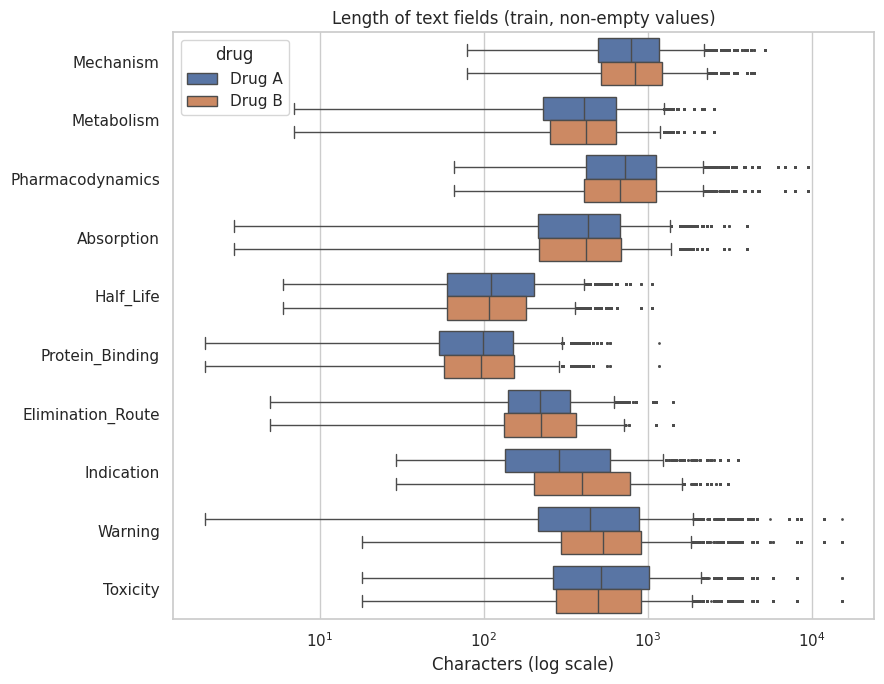

In [13]:
def analyze_text_fields(train, test, schema, eda_dir):
    columns = schema["text_cols"] + schema["category_cols"]
    rows = []
    for col in columns:
        for name, frame in (("train", train), ("test", test)):
            series = frame[col]
            present = series.dropna().astype(str)
            lengths = present.str.len()
            rows.append(
                {
                    "column": col,
                    "dataset": name,
                    "missing": int(series.isna().sum()),
                    "missing_pct": float(series.isna().mean() * 100),
                    "blank_or_whitespace": int((present.str.strip() == "").sum()),
                    "mean_chars": lengths.mean(),
                    "median_chars": lengths.median(),
                    "p95_chars": lengths.quantile(0.95),
                    "max_chars": lengths.max(),
                    "median_words": present.str.split().str.len().median(),
                    "with_html_tags": int(present.str.contains(ANY_TAG_PATTERN).sum()),
                    "with_citation_markers": int(present.str.contains(CITATION_PATTERN).sum()),
                }
            )
    summary = pd.DataFrame(rows)
    summary.to_csv(eda_dir / "text_field_summary.csv", index=False)
    train_rows = summary[summary.dataset == "train"].set_index("column")
    print(f"Text fields analysed: {len(schema['text_cols'])}; categorical list fields: {len(schema['category_cols'])}")
    print("Median characters per text field (train):")
    print(train_rows.loc[schema["text_cols"], "median_chars"].round(0).astype(int).to_string())
    print(f"Blank or whitespace-only values (train): {int(train_rows.blank_or_whitespace.sum())} in {train_rows[train_rows.blank_or_whitespace > 0].index.tolist()}")
    print(f"Values containing HTML tags (train): {int(train_rows.with_html_tags.sum())}; values containing reference markers such as [A123]: {int(train_rows.with_citation_markers.sum())}")

    records = []
    for col in schema["text_cols"]:
        match = re.match(r"^(.*)_([AB])$", col)
        field, side = (match.group(1), f"Drug {match.group(2)}") if match else (col, "Drug")
        lengths = train[col].dropna().astype(str).str.len()
        lengths = lengths[lengths > 0]
        records.append(pd.DataFrame({"field": field, "drug": side, "chars": lengths.values}))
    long_form = pd.concat(records, ignore_index=True)
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.boxplot(data=long_form, y="field", x="chars", hue="drug", fliersize=1, ax=ax)
    ax.set_xscale("log")
    ax.set_title("Length of text fields (train, non-empty values)")
    ax.set_xlabel("Characters (log scale)")
    ax.set_ylabel("")
    save_figure(fig, eda_dir / "text_length_distribution.png")


analyze_text_fields(train, test, schema, folders["eda"])

  column dataset  missing  unique_strings  min_len  median_len  p95_len  max_len  very_short_le_5  multi_component_with_dot  heuristic_invalid
SMILES_A   train        0             920        3        44.0    112.0      903              130                       310                  0
SMILES_A    test        0             730        3        41.0    112.0      903               51                       123                  0
SMILES_B   train        0             490       12        44.0     97.0      903                0                        57                  0
SMILES_B    test        0             405       12        43.0     85.0      404                0                        22                  0
The invalid-looking check only tests the character set and bracket balance; it is not chemical validation.


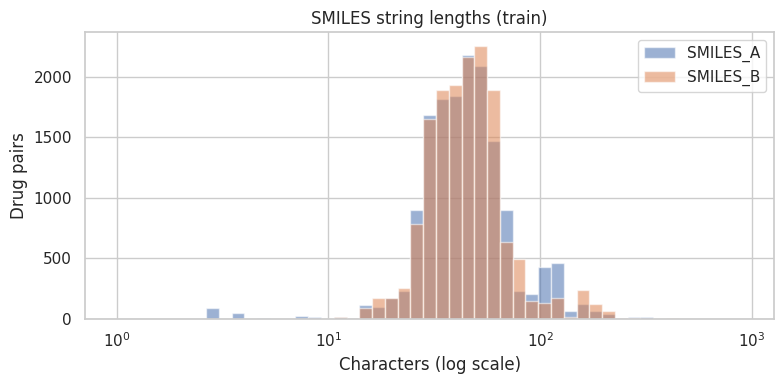

In [14]:
def looks_invalid_smiles(value):
    if not isinstance(value, str) or not value.strip():
        return True
    if not SMILES_ALLOWED_PATTERN.match(value):
        return True
    if value.count("(") != value.count(")") or value.count("[") != value.count("]"):
        return True
    return False


def analyze_smiles(train, test, schema, eda_dir):
    rows = []
    for col in schema["smiles_cols"]:
        for name, frame in (("train", train), ("test", test)):
            series = frame[col]
            lengths = series.dropna().astype(str).str.len()
            rows.append(
                {
                    "column": col,
                    "dataset": name,
                    "missing": int(series.isna().sum()),
                    "unique_strings": int(series.nunique()),
                    "min_len": lengths.min(),
                    "median_len": lengths.median(),
                    "p95_len": lengths.quantile(0.95),
                    "max_len": lengths.max(),
                    "very_short_le_5": int((lengths <= 5).sum()),
                    "multi_component_with_dot": int(series.dropna().str.contains(".", regex=False).sum()),
                    "heuristic_invalid": int(series.map(looks_invalid_smiles).sum()),
                }
            )
    summary = pd.DataFrame(rows)
    summary.to_csv(eda_dir / "smiles_summary.csv", index=False)
    print(summary.round(1).to_string(index=False))
    print("The invalid-looking check only tests the character set and bracket balance; it is not chemical validation.")

    fig, ax = plt.subplots(figsize=(8, 4))
    for col in schema["smiles_cols"]:
        lengths = train[col].dropna().astype(str).str.len()
        ax.hist(lengths, bins=np.logspace(0, np.log10(max(lengths.max(), 10)), 50), alpha=0.55, label=col)
    ax.set_xscale("log")
    ax.set_title("SMILES string lengths (train)")
    ax.set_xlabel("Characters (log scale)")
    ax.set_ylabel("Drug pairs")
    ax.legend()
    save_figure(fig, eda_dir / "smiles_length_distribution.png")


analyze_smiles(train, test, schema, folders["eda"])

Unavailable values per paired field in train (%):
drug            Drug A  Drug B  gap_a_minus_b
field                                        
CYP450_Enzymes    59.5    47.1           12.4
Indication        19.1    11.3            7.8
Warning           31.1    11.3           19.8
Drug A is missing optional fields more often than drug B, so missing-indicator features are added instead of dropping rows.


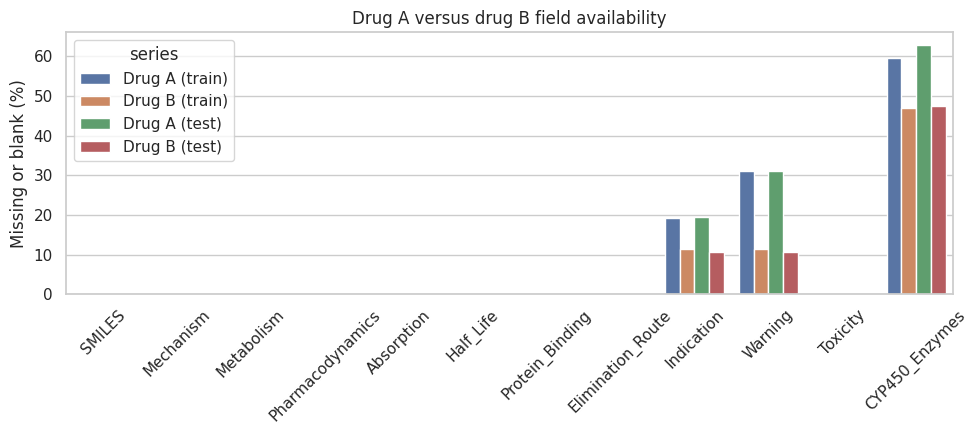

In [15]:
def analyze_drug_availability(train, test, schema, eda_dir):
    rows = []
    for base, sides in schema["paired_fields"].items():
        for name, frame in (("train", train), ("test", test)):
            for suffix, col in sides.items():
                series = frame[col]
                if pd.api.types.is_numeric_dtype(series):
                    unavailable = series.isna()
                else:
                    unavailable = series.isna() | (series.astype(str).str.strip() == "")
                rows.append({"field": base, "drug": f"Drug {suffix}", "dataset": name, "unavailable_pct": float(unavailable.mean() * 100)})
    availability = pd.DataFrame(rows)
    availability.to_csv(eda_dir / "drug_a_vs_b_availability.csv", index=False)
    wide = availability[availability.dataset == "train"].pivot(index="field", columns="drug", values="unavailable_pct")
    wide["gap_a_minus_b"] = wide["Drug A"] - wide["Drug B"]
    gaps = wide[wide[["Drug A", "Drug B"]].max(axis=1) > 0].round(1)
    if gaps.empty:
        print("Every paired field is fully populated for both drugs.")
    else:
        print("Unavailable values per paired field in train (%):")
        print(gaps.to_string())
        print("Drug A is missing optional fields more often than drug B, so missing-indicator features are added instead of dropping rows.")

    availability["series"] = availability["drug"] + " (" + availability["dataset"] + ")"
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.barplot(data=availability, x="field", y="unavailable_pct", hue="series", ax=ax)
    ax.set_title("Drug A versus drug B field availability")
    ax.set_xlabel("")
    ax.set_ylabel("Missing or blank (%)")
    ax.tick_params(axis="x", rotation=45)
    save_figure(fig, eda_dir / "drug_a_vs_b_availability.png")


analyze_drug_availability(train, test, schema, folders["eda"])

## 6. Text preprocessing for NLP



In [16]:
def clean_text_value(value):
    if pd.isna(value):
        return np.nan
    text = INLINE_TAG_PATTERN.sub("", str(value))
    text = ANY_TAG_PATTERN.sub(" ", text)
    text = html.unescape(text)
    text = CITATION_PATTERN.sub("", text)
    text = WHITESPACE_PATTERN.sub(" ", text).strip()
    return text if text else np.nan


def clean_category_value(value):
    if pd.isna(value):
        return np.nan
    text = re.sub(r"\s*,\s*", ",", str(value).strip())
    return text if text else np.nan


def clean_features(frame, schema):
    cleaned = frame.copy()
    for col in schema["text_cols"]:
        cleaned[col] = frame[col].map(clean_text_value)
    for col in schema["category_cols"]:
        cleaned[col] = frame[col].map(clean_category_value)
    return cleaned


def build_drug_text(cleaned, text_cols, suffix):
    pieces = []
    for col in text_cols:
        if col.endswith(f"_{suffix}"):
            label = col[: -(len(suffix) + 1)].replace("_", " ").lower()
            pieces.append(label + ": " + cleaned[col])
    if not pieces:
        return pd.Series("", index=cleaned.index)
    joined = pd.concat(pieces, axis=1)
    return joined.apply(lambda row: " ".join(row.dropna()), axis=1)


def add_text_features(cleaned, schema):
    cleaned["text_drug_a"] = build_drug_text(cleaned, schema["text_cols"], "A")
    cleaned["text_drug_b"] = build_drug_text(cleaned, schema["text_cols"], "B")
    cleaned["combined_text"] = "[DRUG A] " + cleaned["text_drug_a"] + " [DRUG B] " + cleaned["text_drug_b"]
    return cleaned


def report_cleaning(raw, cleaned, schema, name):
    columns = schema["text_cols"] + schema["category_cols"]
    newly_missing = int(cleaned[columns].isna().sum().sum() - raw[columns].isna().sum().sum())
    empty_a = int((cleaned["text_drug_a"] == "").sum())
    empty_b = int((cleaned["text_drug_b"] == "").sum())
    raw_chars = raw[schema["text_cols"]].apply(lambda col: col.fillna("").astype(str).str.len()).sum().sum()
    clean_chars = cleaned[schema["text_cols"]].apply(lambda col: col.fillna("").str.len()).sum().sum()
    print(f"{name}: characters removed by cleaning {1 - clean_chars / raw_chars:.1%}; blank values turned into missing: {newly_missing}; rows with no text for drug A/B: {empty_a}/{empty_b}")


cleaned_train = add_text_features(clean_features(train, schema), schema)
cleaned_test = add_text_features(clean_features(test, schema), schema)
report_cleaning(train, cleaned_train, schema, "train")
report_cleaning(test, cleaned_test, schema, "test")

print()
print(cleaned_train["combined_text"].iloc[0][:600])

train: characters removed by cleaning 5.0%; blank values turned into missing: 21; rows with no text for drug A/B: 0/0
test: characters removed by cleaning 4.9%; blank values turned into missing: 5; rows with no text for drug A/B: 0/0

[DRUG A] mechanism: The alpha and gamma diaminobutyric acid of a positively charged polymyxin B forms an electrostatic interaction with the phosphate groups of a negatively charged lipid A on the outer membrane of a Gram negative bacterium. Calcium and Magnesium ions are displaced from phosphates of the membrane lipids, destabalising the lipopolysaccharide (LPS), increasing membrane permeability, causing cytoplasmic leaking, and killing the cell. Polymyxin B can also bind and neutralize LPS released during bacterial lysis, preventing reactions to endotoxin. A third activity of polymyxin B is t


In [17]:
text_columns_to_save = [id_col, "text_drug_a", "text_drug_b", "combined_text"]
cleaned_train[text_columns_to_save].to_csv(folders["processed"] / "train_text.csv.gz", index=False)
cleaned_test[text_columns_to_save].to_csv(folders["processed"] / "test_text.csv.gz", index=False)
print("Saved cleaned text tables to", folders["processed"])

Saved cleaned text tables to outputs/processed


## 7. TF-IDF feature preparation


In [18]:
def build_tfidf_config(n_documents, max_features, min_df, ngram_max):
    auto_min_df = max(3, int(0.0005 * n_documents))
    return {
        "ngram_range": [1, max(1, ngram_max)],
        "min_df": min_df if min_df else auto_min_df,
        "max_df": 0.95,
        "max_features": max_features,
        "sublinear_tf": True,
        "lowercase": True,
        "strip_accents": None,
        "stop_words": None,
        "token_pattern": TFIDF_TOKEN_PATTERN,
        "dtype": "float32",
    }


def create_tfidf_vectorizer(config):
    params = dict(config)
    params["ngram_range"] = tuple(params["ngram_range"])
    params["dtype"] = np.dtype(params["dtype"]).type
    return TfidfVectorizer(**params)


def prepare_documents(series):
    return series.fillna("").astype(str)


def fit_tfidf(train_documents, config):
    documents = prepare_documents(train_documents)
    if not documents.str.strip().str.len().gt(0).any():
        raise ValueError("All training documents are empty; TF-IDF cannot be fitted")
    vectorizer = create_tfidf_vectorizer(config)
    vectorizer.fit(documents)
    return vectorizer

## 8. Molecular and structured feature preparation


In [19]:
def load_rdkit():
    try:
        from rdkit import Chem, RDLogger
        from rdkit.Chem import rdFingerprintGenerator
    except ImportError:
        return None
    RDLogger.DisableLog("rdApp.*")
    return Chem, rdFingerprintGenerator


def compute_fingerprints(train, test, schema, rdkit_modules, n_bits):
    chemistry, generator_module = rdkit_modules
    generator = generator_module.GetMorganGenerator(radius=2, fpSize=n_bits)
    all_smiles = pd.concat([frame[col] for frame in (train, test) for col in schema["smiles_cols"]]).dropna()
    unique_smiles = list(pd.unique(all_smiles))
    lookup = {smiles: position for position, smiles in enumerate(unique_smiles)}
    matrix = np.zeros((len(unique_smiles) + 1, n_bits), dtype=np.uint8)
    invalid = []
    for smiles, position in lookup.items():
        molecule = chemistry.MolFromSmiles(smiles)
        if molecule is None:
            invalid.append(smiles)
            continue
        matrix[position] = generator.GetFingerprintAsNumPy(molecule)
    lookup_matrix = sparse.csr_matrix(matrix)
    empty_row = len(unique_smiles)

    def stack(frame):
        blocks = []
        for col in schema["smiles_cols"]:
            rows = frame[col].map(lookup).fillna(empty_row).astype(int).to_numpy()
            blocks.append(lookup_matrix[rows])
        return sparse.hstack(blocks, format="csr")

    return stack(train), stack(test), invalid


rdkit_modules = load_rdkit()
fingerprints_created = False
invalid_smiles = []
if rdkit_modules is None:
    print("RDKit is not available, so no fingerprints were created. SMILES quality was checked with a character-set and bracket heuristic only.")
else:
    fingerprint_train, fingerprint_test, invalid_smiles = compute_fingerprints(train, test, schema, rdkit_modules, CONFIG["fingerprint_bits"])
    fingerprints_created = True
    print(f"Fingerprints: train {fingerprint_train.shape}, test {fingerprint_test.shape}")
    print(f"SMILES strings RDKit could not parse: {len(invalid_smiles)}")

Fingerprints: train (15284, 4096), test (3974, 4096)
SMILES strings RDKit could not parse: 0


In [20]:
def build_numeric_features(raw, cleaned, schema, missing_flag_cols):
    features = pd.DataFrame(index=raw.index)
    for suffix in DRUG_SUFFIXES:
        tag = suffix.lower()
        smiles_col = next((c for c in schema["smiles_cols"] if c.endswith(f"_{suffix}")), None)
        if smiles_col:
            features[f"smiles_length_{tag}"] = raw[smiles_col].fillna("").astype(str).str.len()
        side_text = [c for c in schema["text_cols"] if c.endswith(f"_{suffix}")]
        if side_text:
            features[f"text_chars_{tag}"] = cleaned[side_text].apply(lambda col: col.fillna("").str.len()).sum(axis=1)
            features[f"text_fields_present_{tag}"] = cleaned[side_text].notna().sum(axis=1)
    if len(schema["smiles_cols"]) == 2:
        first, second = schema["smiles_cols"]
        features["same_smiles"] = (raw[first] == raw[second]).astype(int)
    for col in missing_flag_cols:
        features[f"missing_{col}"] = cleaned[col].isna().astype(int)
    return features


def build_model_input(raw, cleaned, schema, missing_flag_cols):
    engineered = build_numeric_features(raw, cleaned, schema, missing_flag_cols)
    parts = [engineered]
    if schema["numeric_cols"]:
        parts.append(raw[schema["numeric_cols"]])
    categories = cleaned[schema["category_cols"]].fillna("") if schema["category_cols"] else pd.DataFrame(index=raw.index)
    parts.append(categories)
    model_input = pd.concat(parts, axis=1)
    numeric_names = list(engineered.columns) + list(schema["numeric_cols"])
    return model_input, numeric_names, engineered


def assert_no_leakage_columns(model_input, schema):
    forbidden = set(schema["target_cols"]) | {schema["id_col"]}
    leaked = [c for c in model_input.columns if c in forbidden]
    if leaked:
        raise ValueError(f"Identifier or target columns reached the feature matrix: {leaked}")
    print(f"Feature matrix check passed: {model_input.shape[1]} structured inputs, none are identifiers or targets.")


def fit_structured_preprocessor(model_input, numeric_names, category_cols, train_idx):
    transformers = []
    if numeric_names:
        numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
        transformers.append(("numeric", numeric_pipeline, numeric_names))
    usable_categories = [c for c in category_cols if model_input[c].iloc[train_idx].str.len().gt(0).any()]
    for col in usable_categories:
        vectorizer = CountVectorizer(token_pattern=r"[^,]+", lowercase=False, binary=True)
        transformers.append((f"category_{col}", vectorizer, col))
    preprocessor = ColumnTransformer(transformers, sparse_threshold=1.0)
    preprocessor.fit(model_input.iloc[train_idx])
    return preprocessor, usable_categories


def transform_structured(preprocessor, model_input):
    return sparse.csr_matrix(preprocessor.transform(model_input)).astype(np.float32)


missing_flag_cols = [c for c in schema["text_cols"] + schema["category_cols"] if train[c].isna().any()]
model_input_train, numeric_names, engineered_train = build_model_input(train, cleaned_train, schema, missing_flag_cols)
model_input_test, _, engineered_test = build_model_input(test, cleaned_test, schema, missing_flag_cols)
assert_no_leakage_columns(model_input_train, schema)
print(f"Missing-indicator columns (chosen from train only): {missing_flag_cols}")
display(model_input_train.head(3))

Feature matrix check passed: 15 structured inputs, none are identifiers or targets.
Missing-indicator columns (chosen from train only): ['Indication_A', 'Indication_B', 'Warning_A', 'Warning_B', 'CYP450_Enzymes_A', 'CYP450_Enzymes_B']


,smiles_length_a,text_chars_a,text_fields_present_a,smiles_length_b,text_chars_b,text_fields_present_b,same_smiles,missing_Indication_A,missing_Indication_B,missing_Warning_A,missing_Warning_B,missing_CYP450_Enzymes_A,missing_CYP450_Enzymes_B,CYP450_Enzymes_A,CYP450_Enzymes_B
0,76,4058,8,404,5651,10,0,1,0,1,0,1,1,,
1,39,17696,8,41,32163,10,0,1,0,1,0,1,0,,"CYP2E1,CYP2B6,CYP2A6,CYP2C19,CYP2C8,CYP2C9,CYP..."
2,67,3959,10,57,3802,10,0,0,0,0,0,0,0,CYP3A4,CYP1A1


The imputer, scaler and category vocabularies are fitted in section 11 on training rows only.

## 9. Classification and multilabel data preparation


In [21]:
def prepare_target_arrays(train, schema):
    arrays = {}
    report = {}
    binary_cols = schema["binary_target_cols"]
    if binary_cols:
        report["missing_binary_labels"] = int(train[binary_cols].isna().sum().sum())
        labels = train[binary_cols].to_numpy()
        labels = labels.astype(np.int8) if report["missing_binary_labels"] == 0 else labels.astype(np.float32)
        arrays["binary_labels"] = labels
        arrays["any_event"] = (np.nan_to_num(labels).sum(axis=1) > 0).astype(np.int8)
    if schema["regression_target_cols"]:
        values = train[schema["regression_target_cols"]].to_numpy(dtype=np.float64)
        arrays["regression_targets"] = values
        arrays["regression_positive_mask"] = (values > 0).astype(np.int8)
        report["missing_regression_values"] = int(np.isnan(values).sum())
    if schema["severity_col"]:
        classes = ordered_classes(train[schema["severity_col"]].dropna().unique())
        mapping = {name: i for i, name in enumerate(classes)}
        encoded = train[schema["severity_col"]].map(mapping)
        report["missing_severity_labels"] = int(encoded.isna().sum())
        arrays["severity"] = encoded.fillna(-1).astype(np.int64).to_numpy()
        report["severity_classes"] = classes
    return arrays, report


arrays, target_report = prepare_target_arrays(train, schema)
print("Missing labels and values:", {k: v for k, v in target_report.items() if k.startswith("missing")})
print("Severity classes in order:", target_report.get("severity_classes"))
severity_table = train[schema["severity_col"]].value_counts().reindex(target_report["severity_classes"]).to_frame("pairs")
severity_table["share"] = (severity_table["pairs"] / len(train)).round(3)
display(severity_table)
print(f"Multilabel matrix: {arrays['binary_labels'].shape}; pairs with at least one positive label: {arrays['any_event'].mean():.1%}")

Missing labels and values: {'missing_binary_labels': 0, 'missing_regression_values': 0, 'missing_severity_labels': 0}
Severity classes in order: ['Minor', 'Moderate', 'Major']


,pairs,share
Severity,,
Minor,630,0.041
Moderate,10568,0.691
Major,4086,0.267


Multilabel matrix: (15284, 50); pairs with at least one positive label: 31.5%


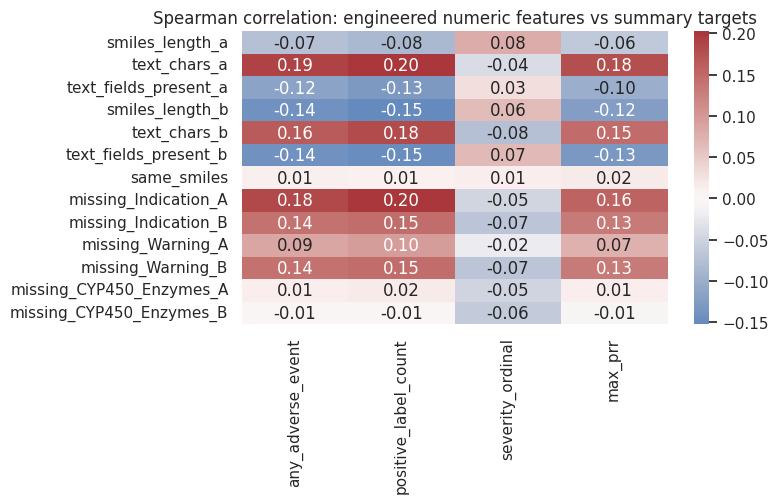

Strongest absolute Spearman correlation between a numeric feature and a summary target: 0.20
Only indicator and length features are correlated with targets; severity is treated as ordinal and flagged as such, and unrelated encodings are never correlated.


In [22]:
def plot_feature_target_correlation(engineered, arrays, report, eda_dir):
    targets = pd.DataFrame(index=engineered.index)
    if "any_event" in arrays:
        targets["any_adverse_event"] = arrays["any_event"]
        targets["positive_label_count"] = np.nan_to_num(arrays["binary_labels"]).sum(axis=1)
    if "severity" in arrays:
        targets["severity_ordinal"] = arrays["severity"]
    if "regression_targets" in arrays:
        targets["max_prr"] = np.nanmax(arrays["regression_targets"], axis=1)
    informative = engineered.loc[:, engineered.nunique() > 1]
    combined = pd.concat([informative, targets], axis=1)
    correlation = combined.corr(method="spearman").loc[informative.columns, targets.columns]
    fig, ax = plt.subplots(figsize=(8, max(4, 0.4 * len(informative.columns))))
    sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
    ax.set_title("Spearman correlation: engineered numeric features vs summary targets")
    save_figure(fig, eda_dir / "feature_target_correlation.png")
    strongest = correlation.abs().max().max()
    print(f"Strongest absolute Spearman correlation between a numeric feature and a summary target: {strongest:.2f}")
    print("Only indicator and length features are correlated with targets; severity is treated as ordinal and flagged as such, and unrelated encodings are never correlated.")


plot_feature_target_correlation(engineered_train, arrays, target_report, folders["eda"])

## 10. Regression data preparation



In [23]:
regression_summary = summarize_regression_targets(train, schema)
display(regression_summary[["column", "zero_fraction", "median", "max", "skew_all_rows", "positive_count"]].head(10).round(3))
print(f"Regression matrix: {arrays['regression_targets'].shape}; missing values: {target_report['missing_regression_values']}")
print(f"Zero fraction across all cells: {(arrays['regression_targets'] == 0).mean():.1%}")

,column,zero_fraction,median,max,skew_all_rows,positive_count
0,Target_PRR_Abdominal_pain,0.785,0.0,130.000,11.758,3286
1,Target_PRR_Anaemia,0.759,0.0,96.667,4.890,3686
2,Target_PRR_Anxiety,0.780,0.0,50.000,6.834,3360
3,Target_PRR_Arthralgia,0.779,0.0,60.000,7.367,3373
4,Target_PRR_Asthenia,0.755,0.0,160.000,12.875,3739
5,Target_PRR_Atrial_fibrillation,0.814,0.0,140.000,8.475,2846
6,Target_PRR_Back_pain,0.788,0.0,120.000,8.671,3237
7,Target_PRR_Chest_pain,0.778,0.0,80.000,6.484,3398
8,Target_PRR_Condition_aggravated,0.816,0.0,60.000,7.849,2807
9,Target_PRR_Confusional_state,0.797,0.0,75.000,8.117,3101


Regression matrix: (15284, 50); missing values: 0
Zero fraction across all cells: 78.5%


In [24]:
display(
    regression_summary[
        ["column", "zero_fraction", "median", "max",
         "skew_all_rows", "positive_count"]
    ].sort_values("zero_fraction", ascending=False).round(3)
)

,column,zero_fraction,median,max,skew_all_rows,positive_count
49,Target_PRR_Weight_increased,0.818,0.0,140.000,16.028,2779
25,Target_PRR_Haemoglobin_decreased,0.818,0.0,90.000,8.553,2781
44,Target_PRR_Somnolence,0.818,0.0,50.000,7.191,2788
45,Target_PRR_Tremor,0.817,0.0,53.333,7.314,2790
8,Target_PRR_Condition_aggravated,0.816,0.0,60.000,7.849,2807
31,Target_PRR_Loss_of_consciousness,0.816,0.0,75.000,9.152,2814
5,Target_PRR_Atrial_fibrillation,0.814,0.0,140.000,8.475,2846
24,Target_PRR_General_physical_health_deterioration,0.814,0.0,70.000,6.438,2848
33,Target_PRR_Myocardial_infarction,0.812,0.0,50.000,9.130,2870
39,Target_PRR_Pruritus,0.812,0.0,40.000,9.420,2879


## 11. Leakage-safe train-validation splitting



In [25]:
def hash_drug_text(frame, columns):
    if not columns:
        return pd.Series("", index=frame.index)
    values = frame[columns].fillna("").astype(str)
    return pd.util.hash_pandas_object(values, index=False).astype(str)


def find_identity_columns(cleaned_train, cleaned_test, schema):
    return [
        c for c in schema["text_cols"]
        if not cleaned_train[c].isna().any() and not cleaned_test[c].isna().any()
    ]


def build_pair_keys(cleaned, schema, identity_cols):
    keys = pd.DataFrame(index=cleaned.index)
    for suffix in DRUG_SUFFIXES:
        side_text = [c for c in identity_cols if c.endswith(f"_{suffix}")]
        smiles_col = next((c for c in schema["smiles_cols"] if c.endswith(f"_{suffix}")), None)
        keys[f"drug_text_{suffix}"] = hash_drug_text(cleaned, side_text).values
        keys[f"drug_smiles_{suffix}"] = cleaned[smiles_col].fillna("").values if smiles_col else ""
    keys["pair_text"] = ["|".join(sorted(p)) for p in zip(keys["drug_text_A"], keys["drug_text_B"])]
    keys["pair_smiles"] = ["|".join(sorted(p)) for p in zip(keys["drug_smiles_A"], keys["drug_smiles_B"])]
    return keys


def build_pair_groups(keys):
    row_count = len(keys)
    rows, columns, offset = [], [], row_count
    for key_name in ("pair_text", "pair_smiles"):
        codes, _ = pd.factorize(keys[key_name])
        rows.append(np.arange(row_count))
        columns.append(codes + offset)
        offset += int(codes.max()) + 1
    rows = np.concatenate(rows)
    columns = np.concatenate(columns)
    graph = sparse.coo_matrix((np.ones(len(rows)), (rows, columns)), shape=(offset, offset))
    _, labels = connected_components(graph, directed=False)
    return pd.factorize(labels[:row_count])[0]


def check_row_order_signal(train, schema):
    col = schema["severity_col"]
    if col is None:
        return False
    bins = np.array_split(np.arange(len(train)), 10)
    top_share = []
    for index in bins:
        counts = train[col].iloc[index].value_counts(normalize=True)
        top_share.append(float(counts.iloc[0]))
    dominant = [train[col].iloc[index].mode().iloc[0] for index in bins]
    sorted_by_label = len(set(dominant)) > 1 and np.mean(top_share) > 0.85
    print(f"Share of the most common {col} class in each tenth of the file: {[round(s, 2) for s in top_share]}")
    if sorted_by_label:
        print(f"WARNING: train.csv is sorted by {col}. Row position and {schema['id_col']} order carry label information, so the ID is excluded from features and every split below is shuffled.")
    return sorted_by_label


def report_group_structure(train, keys_train, groups, schema):
    sizes = pd.Series(groups).value_counts()
    print(f"Row groups (identical drug pair by text or SMILES, order ignored): {len(sizes)} groups for {len(train)} rows")
    print(f"Rows that share a group with another row: {int((sizes[sizes > 1]).sum())}; largest group: {int(sizes.max())} rows")
    col = schema["severity_col"]
    if col:
        conflicts = int((train.groupby(groups)[col].nunique() > 1).sum())
        print(f"Groups whose rows disagree on {col}: {conflicts} (label noise to expect; same-text drug variants such as salts can carry different labels)")


def report_test_coverage(keys_train, keys_test):
    train_drugs = set(keys_train["drug_text_A"]) | set(keys_train["drug_text_B"])
    both_seen = (keys_test["drug_text_A"].isin(train_drugs) & keys_test["drug_text_B"].isin(train_drugs)).mean()
    one_seen = (keys_test["drug_text_A"].isin(train_drugs) | keys_test["drug_text_B"].isin(train_drugs)).mean()
    pair_seen = keys_test["pair_text"].isin(set(keys_train["pair_text"])).mean()
    print(f"Test rows with both drugs already seen in train: {both_seen:.1%}; at least one drug seen: {one_seen:.1%}")
    print(f"Test rows whose drug pair (by text profile) also appears in train: {pair_seen:.1%}")
    if pair_seen > 0.05:
        print("Some test pairs recur in train under different SMILES strings, so the pair-disjoint validation split is slightly stricter than the real test set.")
    return {"both_drugs_seen": float(both_seen), "one_drug_seen": float(one_seen), "pair_seen": float(pair_seen)}


sorted_by_label = check_row_order_signal(train, schema)
identity_cols = find_identity_columns(cleaned_train, cleaned_test, schema)
print(f"Drug identity is judged from {len(identity_cols)} text fields that are never missing.")
keys_train = build_pair_keys(cleaned_train, schema, identity_cols)
keys_test = build_pair_keys(cleaned_test, schema, identity_cols)
groups = build_pair_groups(keys_train)
report_group_structure(train, keys_train, groups, schema)
coverage = report_test_coverage(keys_train, keys_test)

Share of the most common Severity class in each tenth of the file: [1.0, 1.0, 0.67, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.59]
Drug identity is judged from 16 text fields that are never missing.
Row groups (identical drug pair by text or SMILES, order ignored): 9891 groups for 15284 rows
Rows that share a group with another row: 6124; largest group: 94 rows
Groups whose rows disagree on Severity: 279 (label noise to expect; same-text drug variants such as salts can carry different labels)
Test rows with both drugs already seen in train: 99.7%; at least one drug seen: 100.0%
Test rows whose drug pair (by text profile) also appears in train: 38.1%
Some test pairs recur in train under different SMILES strings, so the pair-disjoint validation split is slightly stricter than the real test set.


In [26]:
def make_train_validation_split(strata, groups, seed, validation_fraction):
    n_splits = max(2, int(round(1 / validation_fraction)))
    indices = np.arange(len(strata))
    try:
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        train_idx, val_idx = next(splitter.split(indices, strata, groups))
        method = f"StratifiedGroupKFold(n_splits={n_splits}, shuffle=True), first fold held out"
    except ValueError:
        splitter = GroupShuffleSplit(n_splits=1, test_size=validation_fraction, random_state=seed)
        train_idx, val_idx = next(splitter.split(indices, groups=groups))
        method = "GroupShuffleSplit (stratification was not possible)"
    return np.sort(train_idx), np.sort(val_idx), method


def report_split(train, keys, groups, schema, train_idx, val_idx, any_event, method, coverage):
    print(f"Split strategy: {method}")
    print("  rows are grouped by unordered drug pair so the same pair (including reversed A/B order) never sits on both sides")
    print("  strata combine severity with the any-adverse-event flag so both are balanced across the split")
    print("  the official test set is untouched and kept for final inference")
    overlap = len(set(groups[train_idx]) & set(groups[val_idx]))
    print(f"  train rows: {len(train_idx)}, validation rows: {len(val_idx)}, groups shared between them: {overlap}")
    train_drugs = set(keys["drug_text_A"].iloc[train_idx]) | set(keys["drug_text_B"].iloc[train_idx])
    val_keys = keys.iloc[val_idx]
    both_seen = (val_keys["drug_text_A"].isin(train_drugs) & val_keys["drug_text_B"].isin(train_drugs)).mean()
    print(f"  validation rows with both drugs seen in training rows: {both_seen:.1%} (test versus full train: {coverage['both_drugs_seen']:.1%})")
    if abs(both_seen - coverage["both_drugs_seen"]) < 0.1:
        print("  Individual drugs are shared between train and test, so a drug-disjoint split would be unrealistically pessimistic; a pair-disjoint split avoids pair leakage while keeping that realistic drug overlap.")
    else:
        print("  Drug overlap in validation differs noticeably from test; consider a drug-aware grouping.")
    col = schema["severity_col"]
    if col:
        for name, index in (("train", train_idx), ("validation", val_idx)):
            share = train[col].iloc[index].value_counts(normalize=True).round(3).to_dict()
            print(f"  {col} share in {name}: {share}; any-event rate: {any_event[index].mean():.3f}")
    print("  No package for multilabel iterative stratification is required: stratifying on severity and the any-event flag is the fallback.")
    return overlap


strata = train[schema["severity_col"]].astype(str) + "_" + pd.Series(arrays["any_event"]).astype(str)
train_idx, val_idx, split_method = make_train_validation_split(strata.to_numpy(), groups, SEED, CONFIG["validation_fraction"])
overlap = report_split(train, keys_train, groups, schema, train_idx, val_idx, arrays["any_event"], split_method, coverage)
if overlap:
    raise ValueError("Train and validation share duplicate drug-pair groups")

np.save(folders["splits"] / "train_indices.npy", train_idx)
np.save(folders["splits"] / "validation_indices.npy", val_idx)
assignment = pd.DataFrame({id_col: train[id_col], "split": "train", "group_id": groups})
assignment.loc[val_idx, "split"] = "validation"
assignment.to_csv(folders["splits"] / "split_assignment.csv", index=False)
save_json(
    {
        "method": split_method,
        "seed": SEED,
        "validation_fraction": CONFIG["validation_fraction"],
        "train_rows": len(train_idx),
        "validation_rows": len(val_idx),
        "group_key": "unordered drug pair by hash of never-missing cleaned text fields or by SMILES, merged through connected components",
        "stratification": "severity x any-adverse-event flag",
        "row_order_carries_label_signal": sorted_by_label,
        "test_drug_coverage": coverage,
        "indices_refer_to": "row positions in train.csv",
    },
    folders["splits"] / "split_summary.json",
)

Split strategy: StratifiedGroupKFold(n_splits=5, shuffle=True), first fold held out
  rows are grouped by unordered drug pair so the same pair (including reversed A/B order) never sits on both sides
  strata combine severity with the any-adverse-event flag so both are balanced across the split
  the official test set is untouched and kept for final inference
  train rows: 12274, validation rows: 3010, groups shared between them: 0
  validation rows with both drugs seen in training rows: 99.8% (test versus full train: 99.7%)
  Individual drugs are shared between train and test, so a drug-disjoint split would be unrealistically pessimistic; a pair-disjoint split avoids pair leakage while keeping that realistic drug overlap.
  Severity share in train: {'Moderate': 0.691, 'Major': 0.267, 'Minor': 0.041}; any-event rate: 0.318
  Severity share in validation: {'Moderate': 0.692, 'Major': 0.267, 'Minor': 0.04}; any-event rate: 0.306
  No package for multilabel iterative stratification is requ

In [27]:
def compute_training_weights(arrays, report, schema, train_idx):
    weights = {}
    if "severity" in arrays:
        classes = report["severity_classes"]
        y = arrays["severity"][train_idx]
        valid = y >= 0
        balanced = compute_class_weight("balanced", classes=np.arange(len(classes)), y=y[valid])
        weights["severity_class_weight"] = {name: float(w) for name, w in zip(classes, balanced)}
    if "any_event" in arrays:
        y = arrays["any_event"][train_idx]
        positives = max(int(y.sum()), 1)
        weights["any_event_positive_weight"] = float((len(y) - y.sum()) / positives)
    if "binary_labels" in arrays:
        labels = np.nan_to_num(arrays["binary_labels"][train_idx])
        positives = np.maximum(labels.sum(axis=0), 1)
        negatives = len(labels) - labels.sum(axis=0)
        weights["binary_label_positive_weight"] = {
            short_label(col): float(w) for col, w in zip(schema["binary_target_cols"], negatives / positives)
        }
    return weights


weights = compute_training_weights(arrays, target_report, schema, train_idx)
print("Severity class weights (training rows only):", {k: round(v, 2) for k, v in weights["severity_class_weight"].items()})
print(f"Negative-to-positive ratio of the any-event target: {weights['any_event_positive_weight']:.2f}")

tfidf_config = build_tfidf_config(len(train_idx), CONFIG["max_features"], CONFIG["min_df"], CONFIG["ngram_max"])
vectorizer = fit_tfidf(cleaned_train["combined_text"].iloc[train_idx], tfidf_config)
tfidf_train = vectorizer.transform(prepare_documents(cleaned_train["combined_text"])).astype(np.float32)
tfidf_test = vectorizer.transform(prepare_documents(cleaned_test["combined_text"])).astype(np.float32)
empty_train = int((tfidf_train.getnnz(axis=1) == 0).sum())
empty_test = int((tfidf_test.getnnz(axis=1) == 0).sum())
print(f"TF-IDF vocabulary learned from {len(train_idx)} training documents: {len(vectorizer.vocabulary_)} terms")
print(f"TF-IDF matrices: train {tfidf_train.shape}, test {tfidf_test.shape}; empty documents: train {empty_train}, test {empty_test}")
print("Settings:", tfidf_config)

Severity class weights (training rows only): {'Minor': 8.04, 'Moderate': 0.48, 'Major': 1.25}
Negative-to-positive ratio of the any-event target: 2.15
TF-IDF vocabulary learned from 12274 training documents: 50000 terms
TF-IDF matrices: train (15284, 50000), test (3974, 50000); empty documents: train 0, test 0
Settings: {'ngram_range': [1, 2], 'min_df': 6, 'max_df': 0.95, 'max_features': 50000, 'sublinear_tf': True, 'lowercase': True, 'strip_accents': None, 'stop_words': None, 'token_pattern': '(?u)\\b\\w[\\w\\-/+]*\\b', 'dtype': 'float32'}


In [28]:
preprocessor, usable_categories = fit_structured_preprocessor(model_input_train, numeric_names, schema["category_cols"], train_idx)
structured_train = transform_structured(preprocessor, model_input_train)
structured_test = transform_structured(preprocessor, model_input_test)
structured_names = list(preprocessor.get_feature_names_out())
print(f"Structured matrices: train {structured_train.shape}, test {structured_test.shape}")
print(f"Multi-hot encoded list columns: {usable_categories}")
print("Pair_ID, targets, severity and the any-event flag are not in any feature matrix.")

Structured matrices: train (15284, 47), test (3974, 47)
Multi-hot encoded list columns: ['CYP450_Enzymes_A', 'CYP450_Enzymes_B']
Pair_ID, targets, severity and the any-event flag are not in any feature matrix.


## 12. Save processed datasets and reusable artifacts


In [29]:
def save_array_set(folder, prefix, train_matrix, test_matrix):
    sparse.save_npz(folder / f"{prefix}_train.npz", sparse.csr_matrix(train_matrix))
    sparse.save_npz(folder / f"{prefix}_test.npz", sparse.csr_matrix(test_matrix))


def save_target_arrays(folders, arrays):
    for name, values in arrays.items():
        np.save(folders["features"] / f"y_{name}.npy", values)


joblib.dump(vectorizer, folders["models"] / "tfidf_vectorizer.joblib")
joblib.dump(preprocessor, folders["models"] / "structured_preprocessor.joblib")
save_json(tfidf_config, folders["models"] / "tfidf_config.json")

save_array_set(folders["features"], "X_tfidf", tfidf_train, tfidf_test)
save_array_set(folders["features"], "X_structured", structured_train, structured_test)
if fingerprints_created:
    save_array_set(folders["features"], "X_fingerprint", fingerprint_train, fingerprint_test)
save_target_arrays(folders, arrays)

pd.DataFrame({"feature": vectorizer.get_feature_names_out(), "idf": vectorizer.idf_}).to_csv(folders["features"] / "tfidf_feature_names.csv", index=False)
pd.Series(structured_names, name="feature").to_csv(folders["features"] / "structured_feature_names.csv", index=False)
print("Saved sparse matrices, fitted vectorizer, preprocessor and target arrays")

Saved sparse matrices, fitted vectorizer, preprocessor and target arrays


In [30]:
def build_drug_catalog(frames, schema):
    records = []
    columns_by_suffix = {
        suffix: [c for c in schema["smiles_cols"] + schema["text_cols"] + schema["category_cols"] if c.endswith(f"_{suffix}")]
        for suffix in DRUG_SUFFIXES
    }
    for cleaned, keys in frames:
        for suffix in DRUG_SUFFIXES:
            columns = columns_by_suffix[suffix]
            side = cleaned[columns].copy()
            side.columns = [c[: -(len(suffix) + 1)] for c in columns]
            side.insert(0, "drug_key", keys[f"drug_text_{suffix}"].values)
            records.append(side)
    catalog = pd.concat(records, ignore_index=True).groupby("drug_key", sort=False).first().reset_index()
    catalog.insert(0, "drug_id", [f"drug_{i:04d}" for i in range(len(catalog))])
    return catalog


structured_columns = [id_col] + schema["smiles_cols"] + schema["category_cols"]
train_table = pd.concat([cleaned_train[structured_columns], engineered_train], axis=1)
test_table = pd.concat([cleaned_test[structured_columns], engineered_test], axis=1)
train_table.to_csv(folders["processed"] / "train_structured.csv.gz", index=False)
test_table.to_csv(folders["processed"] / "test_structured.csv.gz", index=False)

target_table = train[[id_col, schema["severity_col"]]].copy()
target_table["Derived_Any_Adverse_Event"] = arrays["any_event"]
target_table = pd.concat([target_table, train[schema["binary_target_cols"] + schema["regression_target_cols"]]], axis=1)
target_table.to_csv(folders["processed"] / "train_targets.csv.gz", index=False)

catalog = build_drug_catalog([(cleaned_train, keys_train), (cleaned_test, keys_test)], schema)
catalog.to_csv(folders["processed"] / "drug_catalog.csv", index=False)
print(f"Drug catalog for the API: {len(catalog)} unique drugs")

Drug catalog for the API: 596 unique drugs


In [31]:
def build_target_definitions(schema, report, weights, arrays):
    tasks = {}
    if schema["severity_col"]:
        tasks["severity_multiclass"] = {
            "target": schema["severity_col"],
            "classes_in_order": report["severity_classes"],
            "encoded_array": "features/y_severity.npy",
            "type": "single-label multiclass, ordinal classes",
            "class_weights_from_train_split": weights.get("severity_class_weight"),
            "metrics_to_compute": ["macro_f1", "balanced_accuracy", "weighted_f1", "accuracy", "per_class_precision_recall", "confusion_matrix", "roc_auc_ovr_macro"],
        }
    if "any_event" in arrays:
        tasks["any_adverse_event_binary"] = {
            "target": "Derived_Any_Adverse_Event",
            "definition": "1 when at least one binary adverse-event label is 1; derived here, not provided by the dataset",
            "encoded_array": "features/y_any_event.npy",
            "positive_weight_from_train_split": weights.get("any_event_positive_weight"),
            "metrics_to_compute": ["accuracy", "precision", "recall", "f1", "confusion_matrix", "roc_auc", "pr_auc"],
        }
        tasks["adverse_event_multilabel"] = {
            "targets": schema["binary_target_cols"],
            "encoded_array": "features/y_binary_labels.npy",
            "type": "multilabel, labels co-occur strongly",
            "positive_weights_from_train_split": weights.get("binary_label_positive_weight"),
            "metrics_to_compute": ["micro_f1", "macro_f1", "weighted_f1", "per_label_precision", "per_label_recall", "hamming_loss", "subset_accuracy", "macro_roc_auc", "macro_pr_auc"],
        }
    if "regression_targets" in arrays:
        tasks["prr_regression"] = {
            "targets": schema["regression_target_cols"],
            "encoded_array": "features/y_regression_targets.npy",
            "positive_mask_array": "features/y_regression_positive_mask.npy",
            "type": "continuous, non-negative, zero-inflated; zero exactly where the matching binary label is 0",
            "transformations_applied": "none",
            "metrics_to_compute": ["mae", "rmse", "r2", "the same metrics on positive-only rows"],
        }
    return tasks


def build_api_schema(schema, report, target_definitions, train, artifact_paths):
    inputs = []
    for col in schema["feature_cols"]:
        if col in schema["smiles_cols"]:
            kind = "smiles"
        elif col in schema["text_cols"]:
            kind = "text"
        elif col in schema["category_cols"]:
            kind = "category_list"
        else:
            kind = "numeric"
        side = col[-1] if re.search(r"_[AB]$", col) else None
        inputs.append({"name": col, "kind": kind, "drug": side, "nullable": bool(train[col].isna().any())})
    outputs = {
        "severity": {"classes": report.get("severity_classes", [])},
        "adverse_events": [
            {
                "display_name": short_label(col).replace("_", " "),
                "binary_column": col,
                "prr_column": next((p for p in schema["regression_target_cols"] if short_label(p) == short_label(col)), None),
            }
            for col in schema["binary_target_cols"]
        ],
        "any_adverse_event": "any_adverse_event_binary" in target_definitions,
    }
    return {
        "pair_input_fields": inputs,
        "drug_catalog": artifact_paths["drug_catalog"],
        "text_input_column": "combined_text",
        "artifacts": artifact_paths,
        "outputs": outputs,
        "notes": [
            "A drug pair is assembled from two drug_catalog rows: A-side fields keep the _A suffix and B-side fields the _B suffix.",
            "Apply the same cleaning functions from preprocessing_eda.py, then the saved TF-IDF vectorizer and structured preprocessor.",
            "Pair_ID is an identifier only and must never be a model input.",
        ],
    }


artifact_paths = {
    "tfidf_vectorizer": "models/tfidf_vectorizer.joblib",
    "structured_preprocessor": "models/structured_preprocessor.joblib",
    "tfidf_train": "features/X_tfidf_train.npz",
    "tfidf_test": "features/X_tfidf_test.npz",
    "structured_train": "features/X_structured_train.npz",
    "structured_test": "features/X_structured_test.npz",
    "fingerprint_train": "features/X_fingerprint_train.npz" if fingerprints_created else None,
    "fingerprint_test": "features/X_fingerprint_test.npz" if fingerprints_created else None,
    "drug_catalog": "processed/drug_catalog.csv",
    "train_indices": "splits/train_indices.npy",
    "validation_indices": "splits/validation_indices.npy",
}
target_definitions = build_target_definitions(schema, target_report, weights, arrays)

save_json(
    {
        "id_column": id_col,
        "smiles_columns": schema["smiles_cols"],
        "text_columns": schema["text_cols"],
        "categorical_list_columns": schema["category_cols"],
        "native_numeric_columns": schema["numeric_cols"],
        "engineered_numeric_columns": [c for c in numeric_names if c not in schema["numeric_cols"]],
        "missing_indicator_source_columns": missing_flag_cols,
        "paired_drug_fields": schema["paired_fields"],
        "severity_column": schema["severity_col"],
        "binary_target_columns": schema["binary_target_cols"],
        "regression_target_columns": schema["regression_target_cols"],
        "excluded_from_features": [id_col] + schema["target_cols"],
        "structured_feature_names": structured_names,
    },
    folders["metadata"] / "column_roles.json",
)
save_json(target_definitions, folders["metadata"] / "target_definitions.json")
save_json(
    {
        "seed": SEED,
        "validation_fraction": CONFIG["validation_fraction"],
        "split_method": split_method,
        "tfidf": tfidf_config,
        "structured_numeric_features": numeric_names,
        "fingerprints": {"created": fingerprints_created, "bits_per_drug": CONFIG["fingerprint_bits"], "unparsable_smiles": len(invalid_smiles)},
        "text_cleaning": "html tags removed, entities decoded, reference markers such as [A123] removed, whitespace collapsed, case and punctuation kept",
        "row_counts": {"train": len(train), "test": len(test)},
        "library_versions": {"scikit_learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
        "artifacts": artifact_paths,
    },
    folders["metadata"] / "preprocessing_config.json",
)
save_json(build_api_schema(schema, target_report, target_definitions, train, artifact_paths), folders["metadata"] / "api_schema.json")
print("Saved metadata to", folders["metadata"])

Saved metadata to outputs/metadata


In [32]:
archive_path = shutil.make_archive("pharma_preprocessing_outputs", "zip", root_dir=".", base_dir=str(OUTPUT_DIR))
print(f"Created {archive_path} ({Path(archive_path).stat().st_size / 1e6:.0f} MB)")
files.download(archive_path)

Created /content/pharma_preprocessing_outputs.zip (129 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. summary

In [33]:
def list_outputs(output_dir):
    print_section("Generated files")
    for path in sorted(output_dir.rglob("*")):
        if path.is_file():
            print(f"{path.relative_to(output_dir.parent)}  ({path.stat().st_size / 1e6:.2f} MB)")


print_section("Shapes")
print(f"train {train.shape}, test {test.shape}, sample_submission {sample.shape}")

print_section("Data-quality findings")
missing_columns = train[schema["feature_cols"]].isna().sum()
print("Feature columns with missing values:", {c: int(n) for c, n in missing_columns[missing_columns > 0].items()})
print(f"Duplicate rows: {int(train.duplicated().sum())}; duplicate identifiers: {int(train[id_col].duplicated().sum())}")
print(f"Train file sorted by {schema['severity_col']}: {sorted_by_label}")
print(f"Severity imbalance (largest to smallest class): {train[schema['severity_col']].value_counts().max() / train[schema['severity_col']].value_counts().min():.1f}:1")
print(f"Pairs with no positive adverse-event label: {1 - arrays['any_event'].mean():.1%}")
print(f"PRR cells that are exactly zero: {(arrays['regression_targets'] == 0).mean():.1%}")

print_section("NLP text fields")
print(schema["text_cols"])

print_section("Target columns")
print(f"Severity: {schema['severity_col']}")
print(f"Binary ({len(schema['binary_target_cols'])}): {schema['binary_target_cols'][:3]} ...")
print(f"Regression ({len(schema['regression_target_cols'])}): {schema['regression_target_cols'][:3]} ...")

print_section("Limitations")
print("- Train is sorted by Severity; row order and Pair_ID were never used.")
print("- Pair-disjoint validation is slightly stricter than the test set because some test pairs recur in train under different SMILES.")
print("- Drug identity comes from text profiles, since the data has no drug identifier column.")
print("- PRR targets are zero-inflated and were left untransformed; consider a two-stage model.")
print("- Combined TF-IDF cannot fully separate drug A and drug B vocabulary; per-drug text is saved for that.")
print("- RDKit fingerprints were " + ("created." if fingerprints_created else "skipped because RDKit is unavailable."))

list_outputs(OUTPUT_DIR)


Shapes
train (15284, 126), test (3974, 25), sample_submission (3974, 102)

Data-quality findings
Feature columns with missing values: {'Indication_A': 2922, 'Indication_B': 1730, 'Warning_A': 4737, 'Warning_B': 1730, 'CYP450_Enzymes_A': 9089, 'CYP450_Enzymes_B': 7193}
Duplicate rows: 0; duplicate identifiers: 0
Train file sorted by Severity: True
Severity imbalance (largest to smallest class): 16.8:1
Pairs with no positive adverse-event label: 68.5%
PRR cells that are exactly zero: 78.5%

NLP text fields
['Mechanism_A', 'Mechanism_B', 'Metabolism_A', 'Metabolism_B', 'Pharmacodynamics_A', 'Pharmacodynamics_B', 'Absorption_A', 'Absorption_B', 'Half_Life_A', 'Half_Life_B', 'Protein_Binding_A', 'Protein_Binding_B', 'Elimination_Route_A', 'Elimination_Route_B', 'Indication_A', 'Indication_B', 'Warning_A', 'Warning_B', 'Toxicity_A', 'Toxicity_B']

Target columns
Severity: Severity
Binary (50): ['Target_Binary_Abdominal_pain', 'Target_Binary_Anaemia', 'Target_Binary_Anxiety'] ...
Regression 

------

# 14 - Severity Classification

#####SETUP

In [35]:
import importlib.util
import subprocess
import sys

# Ensure mlflow is installed
if importlib.util.find_spec("mlflow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mlflow"])

import json
import time
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scipy import sparse
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold

In [36]:
warnings.filterwarnings("ignore")

SEED = 42
OUT = Path("outputs")
for sub in ["models", "metadata", "processed", "figures"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

CLASSES = ["Minor", "Moderate", "Major"]
LABEL_IDS = [0, 1, 2]


def load(name):
    return sparse.load_npz(OUT / f"features/{name}.npz").astype(np.float32).tocsr()



fp = (load("X_fingerprint_train"), load("X_fingerprint_test"))
text = (load("X_tfidf_train"), load("X_tfidf_test"))
num = (load("X_structured_train"), load("X_structured_test"))

FEATURES = {
    "fingerprints": fp,
    "all_sources": (
        sparse.hstack([text[0], fp[0], num[0]]).tocsr(),
        sparse.hstack([text[1], fp[1], num[1]]).tocsr(),
    ),
}

y = np.load(OUT / "features/y_severity.npy")
train_idx = np.load(OUT / "splits/train_indices.npy")
val_idx = np.load(OUT / "splits/validation_indices.npy")
groups = pd.read_csv(OUT / "splits/split_assignment.csv")["group_id"].to_numpy()
test_ids = pd.read_csv(OUT / "processed/test_structured.csv.gz")["Pair_ID"]

y_tr, y_va = y[train_idx], y[val_idx]

assert len(y) == len(groups) == FEATURES["fingerprints"][0].shape[0]
print({k: (v[0].shape, v[1].shape) for k, v in FEATURES.items()})
print("train:", len(train_idx), "| validation:", len(val_idx), "| test:", len(test_ids))
print("class counts (train):", dict(zip(CLASSES, np.bincount(y_tr))))


cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(np.zeros(len(train_idx)), y_tr, groups[train_idx]))



{'fingerprints': ((15284, 4096), (3974, 4096)), 'all_sources': ((15284, 54143), (3974, 54143))}
train: 12274 | validation: 3010 | test: 3974
class counts (train): {'Minor': np.int64(509), 'Moderate': np.int64(8484), 'Major': np.int64(3281)}


###15 - CROSS-VALIDATION

In [37]:
def cross_validate(estimator, X):
    X_tr = X[train_idx]
    macro, minor = [], []
    start = time.time()
    for a, b in folds:
        model = clone(estimator).fit(X_tr[a], y_tr[a])
        pred = model.predict(X_tr[b])
        macro.append(f1_score(y_tr[b], pred, average="macro"))
        minor.append(f1_score(y_tr[b], pred, average=None, labels=LABEL_IDS)[0])
    return {
        "macro_F1": np.mean(macro),
        "macro_F1_std": np.std(macro),
        "F1_Minor": np.mean(minor),
        "seconds": time.time() - start,
    }


def lgbm(n_estimators, num_leaves, class_weight):
    return lgb.LGBMClassifier(
        n_estimators=n_estimators, num_leaves=num_leaves, learning_rate=0.05,
        colsample_bytree=0.3, class_weight=class_weight,
        random_state=SEED, n_jobs=-1, verbose=-1,
    )


def build_candidates(class_weight):
    """class_weight = 'balanced' or None. Same model names in both runs."""
    return {
        "Baseline: always Moderate": ("fingerprints", DummyClassifier(strategy="constant", constant=1)),
        "LogReg | fingerprints": ("fingerprints", LogisticRegression(class_weight=class_weight, max_iter=1000)),
        "LogReg | all sources": ("all_sources", LogisticRegression(class_weight=class_weight, max_iter=1000)),
        "LightGBM 300 trees x 31 leaves": ("fingerprints", lgbm(300, 31, class_weight)),
        "LightGBM 600 trees x 63 leaves": ("fingerprints", lgbm(600, 63, class_weight)),
        "LightGBM 1000 trees x 127 leaves": ("fingerprints", lgbm(1000, 127, class_weight)),
    }


def run_cv_suite(candidates):
    rows = []
    for name, (feature_set, estimator) in candidates.items():
        result = cross_validate(estimator, FEATURES[feature_set][0])
        rows.append({"model": name, "features": feature_set, **result})
        print(f"done: {name} | macro F1 = {result['macro_F1']:.3f} | Minor F1 = {result['F1_Minor']:.3f}")
    return pd.DataFrame(rows)


CANDIDATES = build_candidates("balanced")
cv_results = run_cv_suite(CANDIDATES)
cv_results.to_csv(OUT / "metadata/severity_cv_results.csv", index=False)
display(cv_results.round(3))



done: Baseline: always Moderate | macro F1 = 0.272 | Minor F1 = 0.000
done: LogReg | fingerprints | macro F1 = 0.678 | Minor F1 = 0.460
done: LogReg | all sources | macro F1 = 0.683 | Minor F1 = 0.470
done: LightGBM 300 trees x 31 leaves | macro F1 = 0.728 | Minor F1 = 0.569
done: LightGBM 600 trees x 63 leaves | macro F1 = 0.765 | Minor F1 = 0.617
done: LightGBM 1000 trees x 127 leaves | macro F1 = 0.771 | Minor F1 = 0.621


,model,features,macro_F1,macro_F1_std,F1_Minor,seconds
0,Baseline: always Moderate,fingerprints,0.272,0.002,0.000,0.031
1,LogReg | fingerprints,fingerprints,0.678,0.008,0.460,26.941
2,LogReg | all sources,all_sources,0.683,0.011,0.470,247.412
3,LightGBM 300 trees x 31 leaves,fingerprints,0.728,0.012,0.569,77.121
4,LightGBM 600 trees x 63 leaves,fingerprints,0.765,0.015,0.617,172.785
5,LightGBM 1000 trees x 127 leaves,fingerprints,0.771,0.019,0.621,346.878


## 16 - MODEL SELECTION
Rule: among models within one std of the best, pick the fastest.

In [38]:
best = cv_results.loc[cv_results["macro_F1"].idxmax()]
threshold = best["macro_F1"] - best["macro_F1_std"]
eligible = cv_results[cv_results["macro_F1"] >= threshold]
chosen = eligible.sort_values("seconds").iloc[0]

print(f"Highest mean macro F1 : {best['model']} ({best['macro_F1']:.3f} +/- {best['macro_F1_std']:.3f})")
print(f"Within one std of it  : {eligible['model'].tolist()}")
print(f"Chosen (fastest)      : {chosen['model']}")

chosen_name = chosen["model"]
chosen_features, chosen_estimator = CANDIDATES[chosen_name]

Highest mean macro F1 : LightGBM 1000 trees x 127 leaves (0.771 +/- 0.019)
Within one std of it  : ['LightGBM 600 trees x 63 leaves', 'LightGBM 1000 trees x 127 leaves']
Chosen (fastest)      : LightGBM 600 trees x 63 leaves


## 17 - FINAL EVALUATION ON THE HELD-OUT VALIDATION SPLIT

              precision    recall  f1-score   support

       Minor      0.703     0.645     0.672       121
    Moderate      0.915     0.912     0.913      2084
       Major      0.797     0.814     0.805       805

    accuracy                          0.875      3010
   macro avg      0.805     0.790     0.797      3010
weighted avg      0.875     0.875     0.875      3010



### Validation metrics

,Metric,Score
0,accuracy,0.8748
1,macro_precision,0.8048
2,macro_recall,0.7900
3,macro_f1,0.7969
4,weighted_f1,0.8747
5,f1_minor,0.6724
6,precision_minor,0.7027
7,recall_minor,0.6446
8,f1_moderate,0.9132
9,precision_moderate,0.9148


,Predicted Minor,Predicted Moderate,Predicted Major
Actual Minor,78,33,10
Actual Moderate,27,1900,157
Actual Major,6,144,655


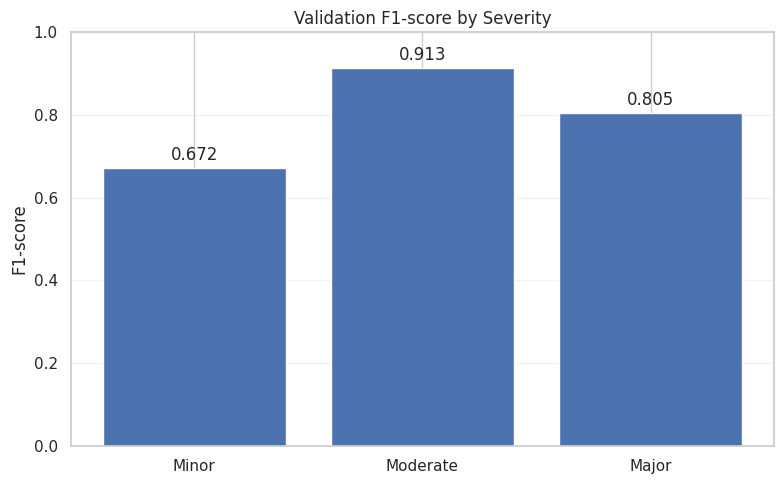

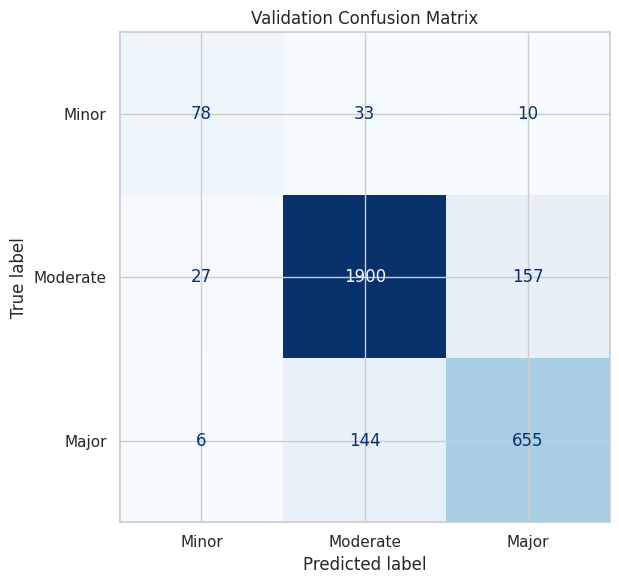

In [39]:
X_train_full, X_test_full = FEATURES[chosen_features]

final_model = clone(chosen_estimator).fit(X_train_full[train_idx], y_tr)
pred_va = final_model.predict(X_train_full[val_idx])

report = classification_report(
    y_va, pred_va, labels=LABEL_IDS, target_names=CLASSES,
    output_dict=True, zero_division=0,
)
print(classification_report(
    y_va, pred_va, labels=LABEL_IDS, target_names=CLASSES, digits=3, zero_division=0,
))


metrics = {
    "accuracy": accuracy_score(y_va, pred_va),
    "macro_precision": precision_score(y_va, pred_va, labels=LABEL_IDS, average="macro", zero_division=0),
    "macro_recall": recall_score(y_va, pred_va, labels=LABEL_IDS, average="macro", zero_division=0),
    "macro_f1": f1_score(y_va, pred_va, labels=LABEL_IDS, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_va, pred_va, labels=LABEL_IDS, average="weighted", zero_division=0),
}
for cls in CLASSES:
    metrics[f"f1_{cls.lower()}"] = report[cls]["f1-score"]
    metrics[f"precision_{cls.lower()}"] = report[cls]["precision"]
    metrics[f"recall_{cls.lower()}"] = report[cls]["recall"]

display(Markdown("### Validation metrics"))
display(pd.DataFrame({"Metric": metrics.keys(), "Score": metrics.values()})
        .style.format({"Score": "{:.4f}"}))


cm = confusion_matrix(y_va, pred_va, labels=LABEL_IDS)
cm_df = pd.DataFrame(cm, index=[f"Actual {c}" for c in CLASSES],
                     columns=[f"Predicted {c}" for c in CLASSES])
display(cm_df)


joblib.dump(final_model, OUT / "models/severity_model.joblib")
pd.DataFrame(report).transpose().to_csv(OUT / "metadata/severity_classification_report.csv")
cm_df.to_csv(OUT / "metadata/severity_confusion_matrix.csv")

test_pred = final_model.predict(X_test_full)
pd.DataFrame({"Pair_ID": test_ids, "Severity": [CLASSES[i] for i in test_pred]}) \
  .to_csv(OUT / "processed/severity_test_predictions.csv", index=False)

with open(OUT / "metadata/severity_final.json", "w") as f:
    json.dump({
        "chosen_model": chosen_name, "features": chosen_features,
        "cv_macro_F1": float(chosen["macro_F1"]),
        "validation_macro_F1": float(metrics["macro_f1"]),
    }, f, indent=2)


fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(CLASSES, [report[c]["f1-score"] for c in CLASSES])
ax.set(title="Validation F1-score by Severity", ylabel="F1-score", ylim=(0, 1))
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
f1_path = OUT / "figures/severity_validation_f1.png"
fig.savefig(f1_path, dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Validation Confusion Matrix")
plt.tight_layout()
cm_path = OUT / "figures/severity_validation_confusion_matrix.png"
fig.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()

## 18 - CLASS-IMBALANCE EXPERIMENT: with vs. without class weights

done: Baseline: always Moderate | macro F1 = 0.272 | Minor F1 = 0.000
done: LogReg | fingerprints | macro F1 = 0.692 | Minor F1 = 0.468
done: LogReg | all sources | macro F1 = 0.695 | Minor F1 = 0.469
done: LightGBM 300 trees x 31 leaves | macro F1 = 0.719 | Minor F1 = 0.531
done: LightGBM 600 trees x 63 leaves | macro F1 = 0.745 | Minor F1 = 0.568
done: LightGBM 1000 trees x 127 leaves | macro F1 = 0.757 | Minor F1 = 0.585


## Class Weight Comparison

,Model,CV Macro F1 (Balanced),CV Macro F1 (No Weights),Macro F1 Change,CV Minor F1 (Balanced),CV Minor F1 (No Weights)
0,Baseline: always Moderate,0.272,0.272,+0.000,0.000,0.000
1,LogReg | fingerprints,0.678,0.692,+0.014,0.460,0.468
2,LogReg | all sources,0.683,0.695,+0.012,0.470,0.469
3,LightGBM 300 trees x 31 leaves,0.728,0.719,-0.009,0.569,0.531
4,LightGBM 600 trees x 63 leaves,0.765,0.745,-0.019,0.617,0.568
5,LightGBM 1000 trees x 127 leaves,0.771,0.757,-0.014,0.621,0.585


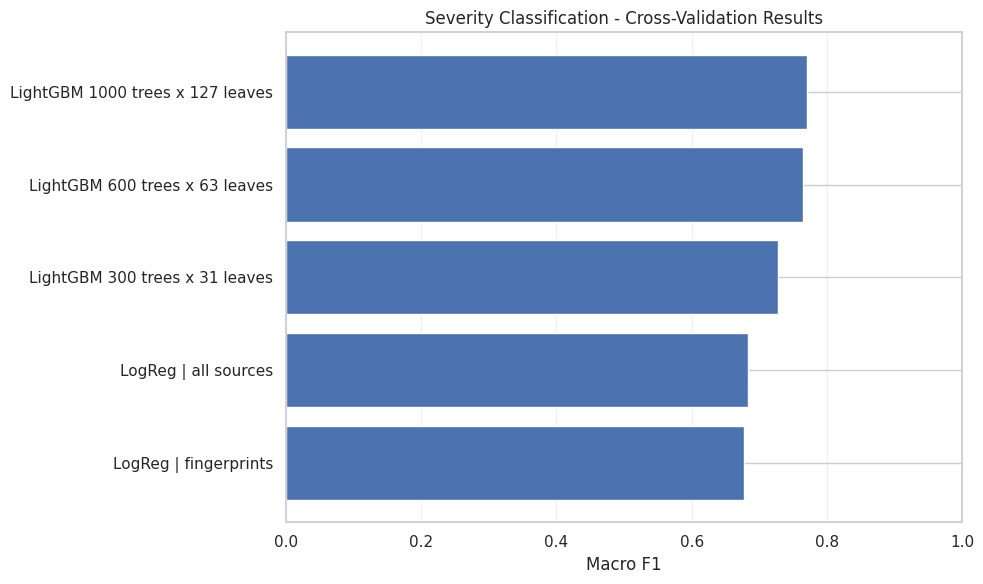

In [40]:
cv_results_no_weight = run_cv_suite(build_candidates(None))

comparison_df = cv_results.merge(
    cv_results_no_weight, on="model", suffixes=(" (Balanced)", " (No Weights)")
)
comparison_df = pd.DataFrame({
    "Model": comparison_df["model"],
    "CV Macro F1 (Balanced)": comparison_df["macro_F1 (Balanced)"],
    "CV Macro F1 (No Weights)": comparison_df["macro_F1 (No Weights)"],
    "Macro F1 Change": comparison_df["macro_F1 (No Weights)"] - comparison_df["macro_F1 (Balanced)"],
    "CV Minor F1 (Balanced)": comparison_df["F1_Minor (Balanced)"],
    "CV Minor F1 (No Weights)": comparison_df["F1_Minor (No Weights)"],
})

display(Markdown("## Class Weight Comparison"))
display(comparison_df.style.format({c: "{:.3f}" for c in comparison_df.columns if c != "Model"}
                                   | {"Macro F1 Change": "{:+.3f}"}))
comparison_df.to_csv(OUT / "metadata/severity_class_weight_comparison.csv", index=False)


plot_df = cv_results[~cv_results["model"].str.contains("Baseline")].sort_values("macro_F1")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df["model"], plot_df["macro_F1"])
ax.set(xlabel="Macro F1", title="Severity Classification - Cross-Validation Results", xlim=(0, 1))
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
cv_plot_path = OUT / "figures/severity_cv_model_comparison.png"
fig.savefig(cv_plot_path, dpi=200, bbox_inches="tight")
plt.show()



## 19 - MLFLOW TRACKING

In [41]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Drug Interaction Severity Classification")


def log_cv_results(results_df, experiment_type, class_weight):
    for _, row in results_df.iterrows():
        with mlflow.start_run(run_name=f"{row['model']} | {experiment_type}"):
            mlflow.log_params({
                "model_name": row["model"],
                "experiment_type": experiment_type,
                "class_weight": class_weight,
                "seed": SEED,
                "validation_strategy": "5-fold Stratified Group CV",
            })
            mlflow.log_metrics({
                "macro_f1": float(row["macro_F1"]),
                "macro_f1_std": float(row["macro_F1_std"]),
                "f1_minor": float(row["F1_Minor"]),
                "runtime_seconds": float(row["seconds"]),
            })
            mlflow.set_tag("experiment_group", experiment_type)


log_cv_results(cv_results, "balanced_class_weights", "balanced")
log_cv_results(cv_results_no_weight, "no_class_weights", "none")


with mlflow.start_run(run_name="Final_Model"):
    mlflow.log_params({
        "model_name": chosen_name,
        "features": chosen_features,
        "class_weight": "balanced",
        "evaluation": "held-out validation split",
    })
    mlflow.log_metrics(metrics)
    for p in [f1_path, cm_path, cv_plot_path,
              OUT / "metadata/severity_classification_report.csv",
              OUT / "models/severity_model.joblib"]:
        mlflow.log_artifact(str(p))


runs_df = mlflow.search_runs(experiment_names=["Drug Interaction Severity Classification"])
display(
    runs_df[["tags.mlflow.runName", "params.experiment_type", "metrics.macro_f1", "metrics.accuracy"]]
    .sort_values("metrics.macro_f1", ascending=False)
    .reset_index(drop=True)
)
print("Total runs:", len(runs_df))


2026/10/27 00:48:20 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/27 00:48:20 INFO mlflow.store.db.utils: Updating database tables
2026/10/27 00:48:22 INFO mlflow.tracking.fluent: Experiment with name 'Drug Interaction Severity Classification' does not exist. Creating a new experiment.


,tags.mlflow.runName,params.experiment_type,metrics.macro_f1,metrics.accuracy
0,Final_Model,None,0.796940,0.874751
1,LightGBM 1000 trees x 127 leaves | balanced_cl...,balanced_class_weights,0.771455,NaN
2,LightGBM 600 trees x 63 leaves | balanced_clas...,balanced_class_weights,0.764507,NaN
3,LightGBM 1000 trees x 127 leaves | no_class_we...,no_class_weights,0.757103,NaN
4,LightGBM 600 trees x 63 leaves | no_class_weights,no_class_weights,0.745204,NaN
5,LightGBM 300 trees x 31 leaves | balanced_clas...,balanced_class_weights,0.727795,NaN
6,LightGBM 300 trees x 31 leaves | no_class_weights,no_class_weights,0.718722,NaN
7,LogReg | all sources | no_class_weights,no_class_weights,0.695415,NaN
8,LogReg | fingerprints | no_class_weights,no_class_weights,0.691812,NaN
9,LogReg | all sources | balanced_class_weights,balanced_class_weights,0.683360,NaN


Total runs: 13


---

# Classification

---

# 20 - M3 — Multilabel Classification of 50 Adverse Events

This section trains and compares multiple multilabel classification models
to predict all 50 binary adverse-event labels.

- Each label represents one adverse event.
- 0 means the adverse event is absent.
- 1 means the adverse event is present.
- Zero values are valid target labels, not missing values.
- Model performance is evaluated using multilabel classification metrics.

### M3.1 — Prepare Features and 50 Target Labels

In [42]:
from scipy import sparse
import numpy as np
import pandas as pd


side_effect_cols = schema["binary_target_cols"]

assert len(side_effect_cols) == 50, (
    f"Expected 50 side-effect labels, found {len(side_effect_cols)}"
)


Y_all = train[side_effect_cols].to_numpy(dtype=np.int8)

assert not pd.isna(train[side_effect_cols]).any().any(), (
    "Missing target values were found. Investigate them before training."
)

assert set(np.unique(Y_all)).issubset({0, 1}), (
    "Target labels must contain only 0 and 1."
)


feature_blocks = [
    sparse.csr_matrix(tfidf_train, dtype=np.float32),
    sparse.csr_matrix(structured_train, dtype=np.float32),
]


if fingerprints_created:
    feature_blocks.append(
        sparse.csr_matrix(fingerprint_train, dtype=np.float32)
    )

X_all = sparse.hstack(feature_blocks, format="csr", dtype=np.float32)


X_train_m3 = X_all[train_idx]
X_val_m3 = X_all[val_idx]

Y_train_m3 = Y_all[train_idx]
Y_val_m3 = Y_all[val_idx]

print("Feature matrix:", X_all.shape)
print("Training features:", X_train_m3.shape)
print("Validation features:", X_val_m3.shape)

print("Training targets:", Y_train_m3.shape)
print("Validation targets:", Y_val_m3.shape)

print("Number of side-effect labels:", len(side_effect_cols))
print("Number of training rows:", len(train_idx))
print("Number of validation rows:", len(val_idx))

Feature matrix: (15284, 54143)
Training features: (12274, 54143)
Validation features: (3010, 54143)
Training targets: (12274, 50)
Validation targets: (3010, 50)
Number of side-effect labels: 50
Number of training rows: 12274
Number of validation rows: 3010


### M3.2 — Analyze Side-Effect Label Distribution

In [43]:
label_summary = pd.DataFrame({
    "side_effect": side_effect_cols,
    "train_zeros": (Y_train_m3 == 0).sum(axis=0),
    "train_ones": (Y_train_m3 == 1).sum(axis=0),
    "validation_zeros": (Y_val_m3 == 0).sum(axis=0),
    "validation_ones": (Y_val_m3 == 1).sum(axis=0),
})

label_summary["train_positive_rate"] = (
    label_summary["train_ones"] /
    len(Y_train_m3)
)

label_summary["validation_positive_rate"] = (
    label_summary["validation_ones"] /
    len(Y_val_m3)
)

label_summary["train_negative_positive_ratio"] = (
    label_summary["train_zeros"] /
    label_summary["train_ones"].replace(0, np.nan)
)

label_summary = label_summary.sort_values(
    "train_positive_rate"
).reset_index(drop=True)

display(label_summary.round(4))

print("\nLabel distribution summary")
print("-" * 45)

print("Total labels:", len(side_effect_cols))
print(
    "Labels with both classes in training:",
    int(
        (
            (label_summary["train_zeros"] > 0) &
            (label_summary["train_ones"] > 0)
        ).sum()
    )
)

print(
    "Labels with no positive training examples:",
    int((label_summary["train_ones"] == 0).sum())
)

print(
    "Labels with no negative training examples:",
    int((label_summary["train_zeros"] == 0).sum())
)

label_summary.to_csv(
    OUTPUT_DIR / "side_effect_label_distribution.csv",
    index=False
)

,side_effect,train_zeros,train_ones,validation_zeros,validation_ones,train_positive_rate,validation_positive_rate,train_negative_positive_ratio
0,Target_Binary_Weight_increased,10021,2253,2484,526,0.1836,0.1748,4.4478
1,Target_Binary_Tremor,10020,2254,2474,536,0.1836,0.1781,4.4454
2,Target_Binary_Somnolence,10016,2258,2480,530,0.1840,0.1761,4.4358
3,Target_Binary_Condition_aggravated,10007,2267,2470,540,0.1847,0.1794,4.4142
4,Target_Binary_Haemoglobin_decreased,9999,2275,2504,506,0.1854,0.1681,4.3952
5,Target_Binary_Loss_of_consciousness,9998,2276,2472,538,0.1854,0.1787,4.3928
6,Target_Binary_Myocardial_infarction,9975,2299,2439,571,0.1873,0.1897,4.3388
7,Target_Binary_General_physical_health_deterior...,9974,2300,2462,548,0.1874,0.1821,4.3365
8,Target_Binary_Atrial_fibrillation,9965,2309,2473,537,0.1881,0.1784,4.3157
9,Target_Binary_Pruritus,9940,2334,2465,545,0.1902,0.1811,4.2588



Label distribution summary
---------------------------------------------
Total labels: 50
Labels with both classes in training: 50
Labels with no positive training examples: 0
Labels with no negative training examples: 0


### M3.3 — Train and Compare Multilabel Models

In [44]:
import joblib

from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    hamming_loss,
    average_precision_score,
)


                                                              # Model 1: One-vs-Rest Logistic Regression


print("Training Model 1: Logistic Regression...")

lr_model = OneVsRestClassifier(
    LogisticRegression(
        solver="liblinear",
        class_weight="balanced",
        max_iter=1000,
        random_state=SEED
    ),
    n_jobs=1
)

lr_model.fit(X_train_m3, Y_train_m3)

lr_pred = lr_model.predict(X_val_m3)
lr_scores = lr_model.predict_proba(X_val_m3)

print("Logistic Regression training completed.")


                                                                   # Model 2: One-vs-Rest Linear SVM


print("\nTraining Model 2: Linear SVM...")

svm_model = OneVsRestClassifier(
    LinearSVC(
        class_weight="balanced",
        random_state=SEED,
        max_iter=3000
    ),
    n_jobs=1
)

svm_model.fit(X_train_m3, Y_train_m3)

svm_pred = svm_model.predict(X_val_m3)
svm_scores = svm_model.decision_function(X_val_m3)

print("Linear SVM training completed.")


                                                                     # Evaluation helper

def evaluate_multilabel_model(
    model_name,
    y_true,
    y_pred,
    y_scores
):

    valid_labels = [
        j for j in range(y_true.shape[1])
        if np.unique(y_true[:, j]).size == 2
    ]

    macro_ap = np.nan

    if valid_labels:
        macro_ap = average_precision_score(
            y_true[:, valid_labels],
            y_scores[:, valid_labels],
            average="macro"
        )

    return {
        "model": model_name,

        "subset_accuracy": accuracy_score(
            y_true, y_pred
        ),

        "micro_precision": precision_score(
            y_true, y_pred,
            average="micro",
            zero_division=0
        ),

        "micro_recall": recall_score(
            y_true, y_pred,
            average="micro",
            zero_division=0
        ),

        "micro_f1": f1_score(
            y_true, y_pred,
            average="micro",
            zero_division=0
        ),

        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0
        ),

        "hamming_loss": hamming_loss(
            y_true, y_pred
        ),

        "macro_average_precision": macro_ap,
    }


                                                                         # Compare both models

results = [
    evaluate_multilabel_model(
        "Logistic Regression",
        Y_val_m3,
        lr_pred,
        lr_scores
    ),

    evaluate_multilabel_model(
        "Linear SVM",
        Y_val_m3,
        svm_pred,
        svm_scores
    )
]

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "macro_f1",
        ascending=False
    ).round(4)
)

results_df.to_csv(
    OUTPUT_DIR / "m3_model_comparison.csv",
    index=False
)

                                                                  # Save the trained models
joblib.dump(
    lr_model,
    OUTPUT_DIR / "models" / "m3_logistic_regression.joblib"
)

joblib.dump(
    svm_model,
    OUTPUT_DIR / "models" / "m3_linear_svm.joblib"
)

print("\nModels and comparison results saved.")

Training Model 1: Logistic Regression...
Logistic Regression training completed.

Training Model 2: Linear SVM...
Linear SVM training completed.


,model,subset_accuracy,micro_precision,micro_recall,micro_f1,macro_f1,weighted_f1,hamming_loss,macro_average_precision
1,Linear SVM,0.5841,0.6662,0.8454,0.7452,0.7429,0.7458,0.1214,0.8291
0,Logistic Regression,0.5963,0.6574,0.8594,0.7450,0.7429,0.7456,0.1235,0.8389



Models and comparison results saved.


----

# 21 - MLflow Setup by Multi level Classification

In [46]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("mlflow") is None:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "mlflow"]
    )

import mlflow
import mlflow.sklearn

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    hamming_loss,
    average_precision_score
)

# Map the actual variable names from the notebook to the expected ones
Y_multi_train = Y_train_m3
Y_multi_val = Y_val_m3

MLFLOW_EXPERIMENT_NAME = "Pharma_Multilabel_50_SideEffects"

mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

Y_multi_train = np.asarray(Y_multi_train).astype(int)
Y_multi_val = np.asarray(Y_multi_val).astype(int)

assert Y_multi_train.shape[1] == 50, (
    f"Expected 50 target labels, got {Y_multi_train.shape[1]}"
)

assert Y_multi_val.shape[1] == 50, (
    f"Expected 50 validation labels, got {Y_multi_val.shape[1]}"
)

print("MLflow version:", mlflow.__version__)
print("Experiment:", MLFLOW_EXPERIMENT_NAME)
print("Training samples:", X_train_m3.shape[0])
print("Validation samples:", X_val_m3.shape[0])
print("Number of side-effect labels:", Y_multi_train.shape[1])
print("Tracking URI:", mlflow.get_tracking_uri())

MLflow version: 3.17.2
Experiment: Pharma_Multilabel_50_SideEffects
Training samples: 12274
Validation samples: 3010
Number of side-effect labels: 50
Tracking URI: sqlite:///mlflow.db


# 22 - Train Models & Track Experiments

In [48]:
multilabel_models = {
    "Logistic_Regression": OneVsRestClassifier(
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            solver="liblinear",
            random_state=SEED
        ),
        n_jobs=-1
    ),

    "Linear_SVM": OneVsRestClassifier(
        LinearSVC(
            class_weight="balanced",
            max_iter=5000,
            random_state=SEED
        ),
        n_jobs=-1
    )
}

mlflow_multilabel_results = []
mlflow_multilabel_models = {}

for model_name, model in multilabel_models.items():

    print(f"\nTraining and tracking: {model_name}")

    with mlflow.start_run(run_name=model_name) as run:

        mlflow.set_tags({
            "task": "multilabel_classification",
            "project": "pharmaceutical_adverse_events",
            "target_type": "50_binary_side_effect_labels",
            "validation_strategy": "group_aware_train_validation_split"
        })

        mlflow.log_params({
            "model": model_name,
            "number_of_labels": Y_multi_train.shape[1],
            "training_samples": X_train_m3.shape[0],
            "validation_samples": X_val_m3.shape[0],
            "class_weight": "balanced",
            "random_state": SEED
        })

        if model_name == "Logistic_Regression":
            mlflow.log_params({
                "max_iter": 1000,
                "solver": "liblinear"
            })
        else:
            mlflow.log_params({
                "max_iter": 5000,
                "kernel": "linear",
                "estimator": "LinearSVC"
            })

        model.fit(X_train_m3, Y_multi_train)

        y_pred = model.predict(X_val_m3)

        if hasattr(model, "predict_proba"):
            y_scores = model.predict_proba(X_val_m3)
        else:
            y_scores = model.decision_function(X_val_m3)

        metrics = {
            "subset_accuracy": accuracy_score(
                Y_multi_val, y_pred
            ),

            "micro_precision": precision_score(
                Y_multi_val, y_pred,
                average="micro",
                zero_division=0
            ),

            "micro_recall": recall_score(
                Y_multi_val, y_pred,
                average="micro",
                zero_division=0
            ),

            "micro_f1": f1_score(
                Y_multi_val, y_pred,
                average="micro",
                zero_division=0
            ),

            "macro_f1": f1_score(
                Y_multi_val, y_pred,
                average="macro",
                zero_division=0
            ),

            "weighted_f1": f1_score(
                Y_multi_val, y_pred,
                average="weighted",
                zero_division=0
            ),

            "hamming_loss": hamming_loss(
                Y_multi_val, y_pred
            ),

            "macro_average_precision": average_precision_score(
                Y_multi_val, y_scores,
                average="macro"
            )
        }

        mlflow.log_metrics({
            metric_name: float(metric_value)
            for metric_name, metric_value in metrics.items()
        })

        per_label_f1 = f1_score(
            Y_multi_val,
            y_pred,
            average=None,
            zero_division=0
        )

        per_label_precision = precision_score(
            Y_multi_val,
            y_pred,
            average=None,
            zero_division=0
        )

        per_label_recall = recall_score(
            Y_multi_val,
            y_pred,
            average=None,
            zero_division=0
        )

        per_label_ap = []

        for j in range(Y_multi_val.shape[1]):
            y_true_label = Y_multi_val[:, j]

            if len(np.unique(y_true_label)) == 2:
                ap = average_precision_score(
                    y_true_label,
                    y_scores[:, j]
                )
            else:
                ap = np.nan

            per_label_ap.append(ap)

        per_label_results = pd.DataFrame({
            "side_effect": schema["binary_target_cols"],
            "precision": per_label_precision,
            "recall": per_label_recall,
            "f1_score": per_label_f1,
            "average_precision": per_label_ap
        })

        per_label_path = (
            OUTPUT_DIR / f"{model_name}_per_label_metrics.csv"
        )

        per_label_results.to_csv(per_label_path, index=False)

        mlflow.log_artifact(str(per_label_path))

        mlflow.sklearn.log_model(
            sk_model=model,
            artifact_path="model"
        )

        mlflow_multilabel_models[model_name] = model

        mlflow_multilabel_results.append({
            "model": model_name,
            "run_id": run.info.run_id,
            **metrics
        })

        print("Run ID:", run.info.run_id)
        print(pd.Series(metrics).round(4).to_string())

print("\nAll multilabel experiments have been logged.")


Training and tracking: Logistic_Regression


2026/10/27 02:11:30 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Run ID: 94fc0ce857aa4f368fb923244731a293
subset_accuracy            0.5963
micro_precision            0.6574
micro_recall               0.8594
micro_f1                   0.7450
macro_f1                   0.7429
weighted_f1                0.7456
hamming_loss               0.1235
macro_average_precision    0.8389

Training and tracking: Linear_SVM


2026/10/27 03:20:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Run ID: bffd787babfa4e6d83948e0b35dd58be
subset_accuracy            0.5844
micro_precision            0.6662
micro_recall               0.8455
micro_f1                   0.7452
macro_f1                   0.7429
weighted_f1                0.7458
hamming_loss               0.1214
macro_average_precision    0.8291

All multilabel experiments have been logged.


# 23 - Compare the Experiments

In [49]:
mlflow_multilabel_comparison = pd.DataFrame(
    mlflow_multilabel_results
)

metric_columns = [
    "subset_accuracy",
    "micro_precision",
    "micro_recall",
    "micro_f1",
    "macro_f1",
    "weighted_f1",
    "hamming_loss",
    "macro_average_precision"
]

display(
    mlflow_multilabel_comparison[
        ["model", "run_id"] + metric_columns
    ].round(4)
)


comparison_path = (
    OUTPUT_DIR / "mlflow_multilabel_model_comparison.csv"
)

mlflow_multilabel_comparison.to_csv(
    comparison_path,
    index=False
)


with mlflow.start_run(
    run_name="Multilabel_Model_Comparison",
    nested=False
):
    mlflow.log_artifact(str(comparison_path))

print("Comparison saved to:", comparison_path)

,model,run_id,subset_accuracy,micro_precision,micro_recall,micro_f1,macro_f1,weighted_f1,hamming_loss,macro_average_precision
0,Logistic_Regression,94fc0ce857aa4f368fb923244731a293,0.5963,0.6574,0.8594,0.7450,0.7429,0.7456,0.1235,0.8389
1,Linear_SVM,bffd787babfa4e6d83948e0b35dd58be,0.5844,0.6662,0.8455,0.7452,0.7429,0.7458,0.1214,0.8291


Comparison saved to: outputs/mlflow_multilabel_model_comparison.csv


# 24 - View Results from MLflow

In [50]:
experiment = mlflow.get_experiment_by_name(
    MLFLOW_EXPERIMENT_NAME
)

runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["metrics.macro_f1 DESC"]
)

display(runs_df)

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.weighted_f1,metrics.macro_f1,metrics.hamming_loss,metrics.micro_recall,metrics.micro_precision,metrics.micro_f1,metrics.macro_average_precision,metrics.subset_accuracy,params.validation_samples,params.kernel,params.max_iter,params.training_samples,params.estimator,params.number_of_labels,params.model,params.random_state,params.class_weight,params.solver,tags.project,tags.mlflow.source.type,tags.task,tags.target_type,tags.mlflow.user,tags.mlflow.source.name,tags.mlflow.runName,tags.validation_strategy
0,bffd787babfa4e6d83948e0b35dd58be,2,FINISHED,/content/mlruns/2/bffd787babfa4e6d83948e0b35dd...,2026-10-27 02:11:39.781000+00:00,2026-10-27 03:20:19.122000+00:00,0.745807,0.742942,0.121369,0.845467,0.666184,0.745194,0.829092,0.584385,3010,linear,5000,12274,LinearSVC,50,Linear_SVM,42,balanced,None,pharmaceutical_adverse_events,NOTEBOOK,multilabel_classification,50_binary_side_effect_labels,root,fileId=19Gep3mS56VPJPr0XoHTbhIouNn_fjsQC,Linear_SVM,group_aware_train_validation_split
1,94fc0ce857aa4f368fb923244731a293,2,FINISHED,/content/mlruns/2/94fc0ce857aa4f368fb923244731...,2026-10-27 01:57:53.817000+00:00,2026-10-27 02:11:39.770000+00:00,0.745556,0.742892,0.123508,0.859395,0.657449,0.744979,0.838879,0.596346,3010,None,1000,12274,None,50,Logistic_Regression,42,balanced,liblinear,pharmaceutical_adverse_events,NOTEBOOK,multilabel_classification,50_binary_side_effect_labels,root,fileId=19Gep3mS56VPJPr0XoHTbhIouNn_fjsQC,Logistic_Regression,group_aware_train_validation_split
2,6221fdd0cbcf46beb6eee959225fca9d,2,FINISHED,/content/mlruns/2/6221fdd0cbcf46beb6eee959225f...,2026-10-27 03:20:31.028000+00:00,2026-10-27 03:20:31.049000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None,None,None,None,None,None,None,NOTEBOOK,None,None,root,fileId=19Gep3mS56VPJPr0XoHTbhIouNn_fjsQC,Multilabel_Model_Comparison,None
3,96d3256a71cc4b97afcff86bf0f5b840,2,FAILED,/content/mlruns/2/96d3256a71cc4b97afcff86bf0f5...,2026-10-27 01:53:18.634000+00:00,2026-10-27 01:57:49.741000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3010,None,1000,12274,None,50,Logistic_Regression,42,balanced,liblinear,pharmaceutical_adverse_events,NOTEBOOK,multilabel_classification,50_binary_side_effect_labels,root,fileId=19Gep3mS56VPJPr0XoHTbhIouNn_fjsQC,Logistic_Regression,group_aware_train_validation_split


---

# 25 - MultiLevel Classification Testing

=========================================

#### 1 - Test on (50) Side Effects

In [51]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    hamming_loss,
    average_precision_score
)


if "mlflow_multilabel_models" in globals() and \
        "Logistic_Regression" in mlflow_multilabel_models:
    test_model = mlflow_multilabel_models["Logistic_Regression"]
elif "multilabel_model" in globals():
    test_model = multilabel_model
else:
    raise NameError(
        "No trained multilabel model found. Run the classification "
        "training cell first."
    )


Y_test_true = np.asarray(Y_multi_val).astype(int)
Y_test_pred = test_model.predict(X_val_m3)

if hasattr(test_model, "predict_proba"):
    Y_test_scores = test_model.predict_proba(X_val_m3)
else:
    Y_test_scores = test_model.decision_function(X_val_m3)


test_metrics = {
    "Subset Accuracy": accuracy_score(Y_test_true, Y_test_pred),
    "Micro Precision": precision_score(
        Y_test_true, Y_test_pred, average="micro", zero_division=0
    ),
    "Micro Recall": recall_score(
        Y_test_true, Y_test_pred, average="micro", zero_division=0
    ),
    "Micro F1": f1_score(
        Y_test_true, Y_test_pred, average="micro", zero_division=0
    ),
    "Macro F1": f1_score(
        Y_test_true, Y_test_pred, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        Y_test_true, Y_test_pred, average="weighted", zero_division=0
    ),
    "Hamming Loss": hamming_loss(Y_test_true, Y_test_pred),
    "Macro Average Precision": average_precision_score(
        Y_test_true, Y_test_scores, average="macro"
    )
}

print("VALIDATION TEST RESULTS")
display(pd.DataFrame(
    test_metrics.items(), columns=["Metric", "Score"]
).round(4))

VALIDATION TEST RESULTS


,Metric,Score
0,Subset Accuracy,0.5963
1,Micro Precision,0.6574
2,Micro Recall,0.8594
3,Micro F1,0.7450
4,Macro F1,0.7429
5,Weighted F1,0.7456
6,Hamming Loss,0.1235
7,Macro Average Precision,0.8389


####2 - Per-Side-Effect Evaluation

In [52]:
from sklearn.metrics import (
    precision_recall_fscore_support,
    average_precision_score
)

per_label_metrics = []

for j, label in enumerate(schema["binary_target_cols"]):
    y_true = Y_test_true[:, j]
    y_pred = Y_test_pred[:, j]
    y_score = Y_test_scores[:, j]

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0
    )

    if len(np.unique(y_true)) == 2:
        ap = average_precision_score(y_true, y_score)
    else:
        ap = np.nan

    per_label_metrics.append({
        "Side Effect": label,
        "Positive Cases": int(y_true.sum()),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Average Precision": ap
    })

per_label_test_df = pd.DataFrame(per_label_metrics)

display(
    per_label_test_df.sort_values("F1 Score", ascending=True)
    .reset_index(drop=True)
    .round(4)
)

per_label_path = OUTPUT_DIR / "multilabel_validation_per_side_effect.csv"
per_label_test_df.to_csv(per_label_path, index=False)

print("Saved per-label validation results to:", per_label_path)

,Side Effect,Positive Cases,Precision,Recall,F1 Score,Average Precision
0,Target_Binary_Pruritus,545,0.5955,0.8349,0.6952,0.7961
1,Target_Binary_General_physical_health_deterior...,548,0.6024,0.8266,0.6969,0.7861
2,Target_Binary_Haemoglobin_decreased,506,0.5796,0.8775,0.6981,0.8042
3,Target_Binary_Weight_increased,526,0.5936,0.8498,0.6990,0.8082
4,Target_Binary_Somnolence,530,0.6120,0.8245,0.7026,0.7988
5,Target_Binary_Condition_aggravated,540,0.6095,0.8556,0.7119,0.7879
6,Target_Binary_Loss_of_consciousness,538,0.6234,0.8309,0.7124,0.8020
7,Target_Binary_Urinary_tract_infection,564,0.6151,0.8528,0.7147,0.8150
8,Target_Binary_Drug_interaction,600,0.6230,0.8400,0.7154,0.8014
9,Target_Binary_Atrial_fibrillation,537,0.6288,0.8454,0.7212,0.8157


Saved per-label validation results to: outputs/multilabel_validation_per_side_effect.csv


#### 3 - Multilabel Prediction Sanity Checks

In [53]:
assert Y_test_true.shape == Y_test_pred.shape, (
    "Mismatch between true labels and predicted labels."
)

assert Y_test_pred.shape[1] == 50, (
    f"Expected 50 predictions per sample, got {Y_test_pred.shape[1]}"
)

assert set(np.unique(Y_test_pred)).issubset({0, 1}), (
    "Predictions must be binary: 0 or 1."
)

print("Validation samples:", Y_test_true.shape[0])
print("Number of side effects:", Y_test_pred.shape[1])
print("Actual positive labels:", int(Y_test_true.sum()))
print("Predicted positive labels:", int(Y_test_pred.sum()))
print(
    "Average predicted side effects per sample:",
    round(float(Y_test_pred.sum(axis=1).mean()), 3)
)
print("All sanity checks passed.")

Validation samples: 3010
Number of side effects: 50
Actual positive labels: 31592
Predicted positive labels: 41296
Average predicted side effects per sample: 13.72
All sanity checks passed.


-----

# 26 - Regression

-------

In [54]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import mlflow
import xgboost as xgb
from scipy.sparse import hstack
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import Descriptors
from scipy import sparse as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.multioutput import MultiOutputRegressor
import lightgbm as lgb
from IPython.display import display

In [55]:
# ------------------------------------------------------------------
# Feature builders. The SAME functions build train AND test features
# (the old version rebuilt test from saved .npz files with a different
#  layout and then cut columns, so train and test columns did not match).
# ------------------------------------------------------------------
N_BITS = 1024
USE_TEXT_SVD = True
SVD_COMPONENTS = 300

DESC_FUNCS = [
    Descriptors.MolWt, Descriptors.MolLogP, Descriptors.TPSA,
    Descriptors.NumHDonors, Descriptors.NumHAcceptors,
    Descriptors.NumRotatableBonds, Descriptors.RingCount, Descriptors.HeavyAtomCount,
]
_mol_cache = {}


def get_mol_features(smiles):
    """Morgan bits + a few RDKit descriptors for one SMILES (cached)."""
    key = str(smiles)
    if key in _mol_cache:
        return _mol_cache[key]
    fp = np.zeros(N_BITS, dtype=np.float32)
    desc = np.zeros(len(DESC_FUNCS), dtype=np.float32)
    try:
        mol = Chem.MolFromSmiles(key)
        if mol:
            fp = np.array(AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=N_BITS), dtype=np.float32)
            desc = np.array([f(mol) for f in DESC_FUNCS], dtype=np.float32)
    except Exception:
        pass
    desc = np.clip(np.nan_to_num(desc, nan=0.0, posinf=0.0, neginf=0.0), -1e6, 1e6)
    _mol_cache[key] = (fp, desc)
    return _mol_cache[key]


def build_chem_features(frame):
    """Order-independent (A,B) == (B,A) features:
       fingerprint SUM and AND (|A-B| is redundant: it equals SUM - 2*AND),
       descriptor SUM and |A-B|."""
    smi_a = frame["SMILES_A"].astype(str).to_numpy()
    smi_b = frame["SMILES_B"].astype(str).to_numpy()
    uniq = pd.unique(np.concatenate([smi_a, smi_b]))
    pos = {s: k for k, s in enumerate(uniq)}
    fp_u = np.zeros((len(uniq), N_BITS), dtype=np.uint8)
    desc_u = np.zeros((len(uniq), len(DESC_FUNCS)), dtype=np.float32)
    for s, k in pos.items():
        fp, desc = get_mol_features(s)
        fp_u[k] = fp
        desc_u[k] = desc
    ia = np.fromiter((pos[s] for s in smi_a), dtype=np.int64, count=len(smi_a))
    ib = np.fromiter((pos[s] for s in smi_b), dtype=np.int64, count=len(smi_b))
    fa, fb = fp_u[ia], fp_u[ib]
    da, db = desc_u[ia], desc_u[ib]
    dense = np.hstack([
        (fa + fb).astype(np.float32),
        (fa * fb).astype(np.float32),
        da + db,
        np.abs(da - db),
    ])
    return sp.csr_matrix(dense)


def combine_text(frame):
    return frame[schema['text_cols']].fillna("").astype(str).agg(" ".join, axis=1)


X_chem_train = build_chem_features(train)
X_chem_test = build_chem_features(test)

tfidf = TfidfVectorizer(max_features=3000, token_pattern=TFIDF_TOKEN_PATTERN)
X_text_train = tfidf.fit_transform(combine_text(train))
X_text_test = tfidf.transform(combine_text(test))
if USE_TEXT_SVD:
    n_comp = max(2, min(SVD_COMPONENTS, X_text_train.shape[1] - 1, X_text_train.shape[0] - 1))
    svd = TruncatedSVD(n_components=n_comp, random_state=SEED)
    X_text_train = sp.csr_matrix(svd.fit_transform(X_text_train).astype(np.float32))
    X_text_test = sp.csr_matrix(svd.transform(X_text_test).astype(np.float32))

X_reg_all = hstack([X_chem_train, X_text_train]).tocsr()
X_test_input = hstack([X_chem_test, X_text_test]).tocsr()
assert X_reg_all.shape[1] == X_test_input.shape[1], "train/test feature mismatch"

y_all = train[schema['regression_target_cols']].values

X_tr, X_val = X_reg_all[train_idx], X_reg_all[val_idx]
Y_tr, Y_val = y_all[train_idx], y_all[val_idx]

regression_cols = schema['regression_target_cols']
results_list = []

print(f"X train(all rows): {X_reg_all.shape} | X test: {X_test_input.shape}")
print(f"Group split -> train: {X_tr.shape[0]} rows, validation: {X_val.shape[0]} rows")
print(f"\n start training on {len(regression_cols)} column \n")

X train(all rows): (15284, 2364) | X test: (3974, 2364)
Group split -> train: 12274 rows, validation: 3010 rows

 start training on 50 column 



In [56]:
regression_cols = schema['regression_target_cols']
target_indices = [train[schema['target_cols']].columns.get_loc(c) for c in regression_cols]

Y_tr_log = np.log1p(np.maximum(0, Y_tr))
Y_val_log = np.log1p(np.maximum(0, Y_val))

### Training helpers (early stopping, hurdle combination)
- XGBoost with more trees + early stopping on an **inner holdout taken from the training part only** (the validation set is never used for stopping).
- Regressor works on `log1p` with an optional bias correction (smearing) when converting back.
- `combine()` = `prob * reg`, with an optional threshold (`th=0` means no threshold).

In [57]:
def detect_xgb_device():
    try:
        probe = xgb.XGBClassifier(n_estimators=1, tree_method='hist', device='cuda')
        probe.fit(np.random.rand(20, 3), np.array([0, 1] * 10))
        return 'cuda'
    except Exception:
        return 'cpu'

DEVICE = detect_xgb_device()
print("XGBoost device:", DEVICE)

MIN_POS = 20
MAX_TREES = 1000
ES_ROUNDS = 30
SHARED = dict(
    learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.4,
    min_child_weight=3, reg_lambda=2.0, random_state=SEED,
    tree_method='hist', device=DEVICE,
)


class ConstProb:
    def __init__(self, p):
        self.p = float(p)
    def predict_proba(self, X):
        n = X.shape[0]
        return np.column_stack([np.full(n, 1 - self.p), np.full(n, self.p)])


class ConstLog:
    def __init__(self, value):
        self.value = float(value)
    def predict(self, X):
        return np.full(X.shape[0], self.value)


def inner_split(n, frac=0.1):
    idx = np.random.RandomState(SEED).permutation(n)
    k = max(1, int(n * frac))
    return idx[k:], idx[:k]


def fit_clf(X, y, n_iter=None):
    """n_iter=None -> early stopping on an inner holdout. Returns (model, n_trees_used)."""
    if y.min() == y.max():
        return ConstProb(y[0]), 0
    if n_iter is None:
        tr, ho = inner_split(X.shape[0])
        if len(np.unique(y[tr])) == 2 and len(np.unique(y[ho])) == 2:
            m = xgb.XGBClassifier(n_estimators=MAX_TREES, early_stopping_rounds=ES_ROUNDS,
                                  eval_metric='logloss', **SHARED)
            m.fit(X[tr], y[tr], eval_set=[(X[ho], y[ho])], verbose=False)
            return m, int(m.best_iteration) + 1
        n_iter = 300
    n_iter = int(n_iter) if n_iter > 0 else 100
    m = xgb.XGBClassifier(n_estimators=n_iter, eval_metric='logloss', **SHARED)
    m.fit(X, y, verbose=False)
    return m, n_iter


def fit_reg(Xp, yp, n_iter=None):
    """Regressor on positive rows only, trained on log1p(y).
    Returns (model, n_trees_used, smear). smear = bias-correction factor from holdout residuals."""
    if Xp.shape[0] <= MIN_POS:
        mean_val = float(yp.mean()) if len(yp) else 0.0
        return ConstLog(np.log1p(mean_val)), 0, 1.0
    ylog = np.log1p(yp)
    if n_iter is None:
        if Xp.shape[0] >= 100:
            tr, ho = inner_split(Xp.shape[0])
            m = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=MAX_TREES,
                                 early_stopping_rounds=ES_ROUNDS, eval_metric='rmse', **SHARED)
            m.fit(Xp[tr], ylog[tr], eval_set=[(Xp[ho], ylog[ho])], verbose=False)
            res = ylog[ho] - np.asarray(m.predict(Xp[ho]), dtype=float)
            smear = float(np.clip(np.mean(np.exp(res)), 1.0, 3.0))
            return m, int(m.best_iteration) + 1, smear
        n_iter = 200
    n_iter = int(n_iter) if n_iter > 0 else 200
    m = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=n_iter, eval_metric='rmse', **SHARED)
    m.fit(Xp, ylog, verbose=False)
    return m, n_iter, 1.0


def combine(prob, reg_log, smear, use_smear, th):
    """Hurdle prediction. smear is applied on the (1+y) scale: y = smear*exp(pred) - 1."""
    s = np.asarray(smear)[None, :] if use_smear else 1.0
    reg = np.maximum(0.0, s * np.exp(reg_log) - 1.0)
    out = prob * reg
    if th > 0:
        out = np.where(prob >= th, out, 0.0)
    return out

XGBoost device: cuda


In [58]:
Y_tr_bin = (Y_tr > 0).astype(int)
Y_val_bin = (Y_val > 0).astype(int)

val_prob_list, val_reglog_list = [], []
val_smear, clf_iters, reg_iters = [], [], []

for i, col in enumerate(regression_cols):
    clf, n_c = fit_clf(X_tr, Y_tr_bin[:, i])
    val_prob_list.append(clf.predict_proba(X_val)[:, 1])
    clf_iters.append(n_c)

    pos_mask_tr = Y_tr_bin[:, i] == 1
    reg, n_r, sm = fit_reg(X_tr[pos_mask_tr], Y_tr[pos_mask_tr, i])
    val_reglog_list.append(np.asarray(reg.predict(X_val), dtype=float))
    val_smear.append(sm)
    reg_iters.append(n_r)

    if (i + 1) % 10 == 0 or (i + 1) == len(regression_cols):
        print(f"  trained {i + 1}/{len(regression_cols)} targets")

val_probs_mat = np.column_stack(val_prob_list)
val_reglog_mat = np.column_stack(val_reglog_list)
val_smear = np.array(val_smear)

grid_rows = []
for use_smear in (False, True):
    for th in [0.0] + [round(t, 2) for t in np.arange(0.1, 0.6, 0.05)]:
        preds = combine(val_probs_mat, val_reglog_mat, val_smear, use_smear, th)
        grid_rows.append({
            "use_smear": use_smear, "th": th,
            "mean_r2": r2_score(Y_val, preds, multioutput='raw_values').mean(),
            "mean_rmse": np.sqrt(mean_squared_error(Y_val, preds, multioutput='raw_values')).mean(),
        })
grid = pd.DataFrame(grid_rows).sort_values("mean_r2", ascending=False).reset_index(drop=True)
print("Top configurations on validation:")
display(grid.head(8).round(4))

best_use_smear = bool(grid.loc[0, "use_smear"])
best_th = float(grid.loc[0, "th"])
print(f"best config -> smearing: {best_use_smear} | threshold: {best_th:.2f} (0.00 = no threshold)")

final_optimized_preds = combine(val_probs_mat, val_reglog_mat, val_smear, best_use_smear, best_th)

opt_rmse = np.sqrt(mean_squared_error(Y_val, final_optimized_preds, multioutput='raw_values'))
opt_mae = mean_absolute_error(Y_val, final_optimized_preds, multioutput='raw_values')
opt_r2 = r2_score(Y_val, final_optimized_preds, multioutput='raw_values')

pos_r2 = []
for i in range(Y_val.shape[1]):
    m = Y_val[:, i] > 0
    if m.sum() > 1:
        pos_r2.append(r2_score(Y_val[m, i], final_optimized_preds[m, i]))
print(f"Mean R2 on all rows: {opt_r2.mean():.4f} | Mean R2 on positive rows only: {np.mean(pos_r2):.4f}")

optimized_summary = pd.DataFrame({
    "model": [
        "LightGBM (old)",
        "XGBoost (old)",
        f"Hurdle v2 (group split, early stopping, th={best_th:.2f}, smear={best_use_smear})"
    ],
    "Mean RMSE ": [2.2794, 2.2989, round(opt_rmse.mean(), 4)],
    "Mean MAE ": [0.7727, 0.7861, round(opt_mae.mean(), 4)],
    "Mean R² ": [0.1359, 0.1207, round(opt_r2.mean(), 4)]
})

print("\n" + "=" * 65)
print("Comparison of Regression Models with Hurdle Model v2")
print("=" * 65)
display(optimized_summary)

  trained 10/50 targets
  trained 20/50 targets
  trained 30/50 targets
  trained 40/50 targets
  trained 50/50 targets
Top configurations on validation:


,use_smear,th,mean_r2,mean_rmse
0,True,0.00,0.1785,2.3769
1,True,0.10,0.1760,2.3806
2,False,0.00,0.1751,2.3847
3,False,0.10,0.1727,2.3881
4,True,0.15,0.1720,2.3863
5,False,0.15,0.1690,2.3932
6,True,0.20,0.1675,2.3927
7,False,0.20,0.1649,2.3991


best config -> smearing: True | threshold: 0.00 (0.00 = no threshold)
Mean R2 on all rows: 0.1785 | Mean R2 on positive rows only: -0.2316

Comparison of Regression Models with Hurdle Model v2


,model,Mean RMSE,Mean MAE,Mean R²
0,LightGBM (old),2.2794,0.7727,0.1359
1,XGBoost (old),2.2989,0.7861,0.1207
2,"Hurdle v2 (group split, early stopping, th=0.0...",2.3769,0.9053,0.1785


---

# 27 - Test

---

In [59]:
assert X_test_input.shape[1] == X_reg_all.shape[1] == X_tr.shape[1], "train/test feature mismatch"
print(f"X_test_input shape: {X_test_input.shape} (matches train: {X_tr.shape[1]} columns)")

X_test_input shape: (3974, 2364) (matches train: 2364 columns)


In [60]:
Y_all_bin = (y_all > 0).astype(int)

test_prob_list, test_reglog_list = [], []
for i, col in enumerate(regression_cols):
    n_c = int(round(clf_iters[i] * 1.1)) if clf_iters[i] > 0 else 0
    clf, _ = fit_clf(X_reg_all, Y_all_bin[:, i], n_iter=n_c)
    test_prob_list.append(clf.predict_proba(X_test_input)[:, 1])

    pos_mask = Y_all_bin[:, i] == 1
    n_r = int(round(reg_iters[i] * 1.1)) if reg_iters[i] > 0 else 0
    reg, _, _ = fit_reg(X_reg_all[pos_mask], y_all[pos_mask, i], n_iter=n_r)
    test_reglog_list.append(np.asarray(reg.predict(X_test_input), dtype=float))

    if (i + 1) % 10 == 0 or (i + 1) == len(regression_cols):
        print(f"  refit {i + 1}/{len(regression_cols)} targets")

test_probs_mat = np.column_stack(test_prob_list)
test_reglog_mat = np.column_stack(test_reglog_list)

final_test_predictions = combine(test_probs_mat, test_reglog_mat, val_smear, best_use_smear, best_th)
final_test_predictions = np.clip(final_test_predictions, 0, None)

assert final_test_predictions.shape == (len(test), len(regression_cols))
assert np.isfinite(final_test_predictions).all(), "NaN/inf in predictions"
print("Predictions:", final_test_predictions.shape,
      "| share of zeros:", round(float((final_test_predictions == 0).mean()), 3),
      "| train share of zeros:", round(float((y_all == 0).mean()), 3))

  refit 10/50 targets
  refit 20/50 targets
  refit 30/50 targets
  refit 40/50 targets
  refit 50/50 targets
Predictions: (3974, 50) | share of zeros: 0.0 | train share of zeros: 0.785


---

# 28 - Submission file ( for competition)

---

In [61]:
sub_final = sample.copy()
sub_final[regression_cols] = final_test_predictions
sub_file_path = folders["models"] / f"final_submission_hurdle_th_{best_th:.2f}.csv"
sub_final.to_csv(sub_file_path, index=False)
print(f"saved to {sub_file_path}")

saved to outputs/models/final_submission_hurdle_th_0.00.csv


# 29 - ML flow

In [62]:
mlflow.set_experiment("Drug_Interaction_Regression")
with mlflow.start_run(run_name=f"Final_Test_Submission_Th_{best_th:.2f}"):
    mlflow.log_params({
        "model": "Hurdle Model v2 (XGBoost, early stopping, group split)",
        "optimal_threshold": float(best_th),
        "use_smearing": bool(best_use_smear),
        "text_features": "TruncatedSVD" if USE_TEXT_SVD else "TF-IDF",
        "n_features": int(X_reg_all.shape[1]),
        "xgb_device": DEVICE,
        "test_rows": len(test)
    })
    mlflow.log_metrics({
        "val_mean_r2": float(opt_r2.mean()),
        "val_mean_r2_positive_rows": float(np.mean(pos_r2)),
        "val_mean_rmse": float(opt_rmse.mean()),
        "val_mean_mae": float(opt_mae.mean()),
    })
    mlflow.log_artifact(str(sub_file_path))
    print("Done Alhamdulillah! ^_^")

2026/10/27 03:37:06 INFO mlflow.tracking.fluent: Experiment with name 'Drug_Interaction_Regression' does not exist. Creating a new experiment.


Done Alhamdulillah! ^_^


# 30 - Comparison of the 3 tasks (validation results)
All numbers below are on the **same leakage-safe validation split** (`val_idx`). The metrics differ by task type, so each task has its own headline metric and the scores are not directly comparable.
1. **Severity classification** (Minor / Moderate / Major)
2. **Multilabel classification** of the 50 side effects
3. **PRR regression**, evaluated on **non-zero symptoms only** (regressor head, no probability multiplication)

In [63]:
from IPython.display import display, Markdown
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, roc_auc_score, r2_score, mean_squared_error, mean_absolute_error)


def need(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise NameError(f"Run the earlier cells first - missing: {missing}")


                                                              # TASK 1 - Severity classification

need("final_model", "X_train_full", "val_idx", "CLASSES", "LABEL_IDS", "OUT", "chosen", "chosen_name")

y_sev = np.load(OUT / "features/y_severity.npy")[val_idx]
X_sev_val = X_train_full[val_idx]
pred_sev = final_model.predict(X_sev_val)

p, r, f, s = precision_recall_fscore_support(y_sev, pred_sev, labels=LABEL_IDS, zero_division=0)
sev_overall = {
    "Accuracy": accuracy_score(y_sev, pred_sev),
    "Balanced accuracy": balanced_accuracy_score(y_sev, pred_sev),
    "Macro precision": p.mean(),
    "Macro recall": r.mean(),
    "Macro F1": f.mean(),
    "Weighted F1": f1_score(y_sev, pred_sev, labels=LABEL_IDS, average="weighted", zero_division=0),
}
try:
    sev_overall["ROC-AUC (OvR, macro)"] = roc_auc_score(
        y_sev, final_model.predict_proba(X_sev_val), multi_class="ovr", average="macro", labels=LABEL_IDS)
except Exception:
    pass
sev_overall["CV macro F1 (train folds)"] = float(chosen["macro_F1"])

sev_per_class = pd.DataFrame({"Class": CLASSES, "Precision": p, "Recall": r, "F1": f, "Support": s})
sev_cm = pd.DataFrame(
    pd.crosstab(pd.Series(y_sev, name="Actual"), pd.Series(pred_sev, name="Predicted"))
      .reindex(index=LABEL_IDS, columns=LABEL_IDS, fill_value=0).values,
    index=[f"Actual {c}" for c in CLASSES], columns=[f"Predicted {c}" for c in CLASSES])

display(Markdown(f"## Task 1 - Severity classification  ({chosen_name})"))
display(pd.DataFrame({"Metric": sev_overall.keys(), "Score": sev_overall.values()}).round(4))
display(sev_per_class.round(4))
display(sev_cm)

                                                     # TASK 2 - Multilabel classification of the 50 side effects

need("test_metrics", "per_label_test_df", "test_model", "Y_test_true")

ml_overall = dict(test_metrics)
f1s = per_label_test_df["F1 Score"]
ml_overall["Mean per-label F1"] = f1s.mean()
ml_overall["Median per-label F1"] = f1s.median()
ml_overall["Mean per-label Average Precision"] = per_label_test_df["Average Precision"].mean()
ml_overall["Labels with F1 = 0"] = int((f1s == 0).sum())

display(Markdown(f"## Task 2 - Multilabel classification of {Y_test_true.shape[1]} side effects  ({type(test_model).__name__})"))
display(pd.DataFrame({"Metric": ml_overall.keys(), "Score": ml_overall.values()}).round(4))
display(Markdown("**5 hardest side effects (lowest F1)**"))
display(per_label_test_df.sort_values("F1 Score").head(5).reset_index(drop=True).round(4))
display(Markdown("**5 easiest side effects (highest F1)**"))
display(per_label_test_df.sort_values("F1 Score", ascending=False).head(5).reset_index(drop=True).round(4))

                                                   # TASK 3 - PRR regression, NON-ZERO symptoms only

need("val_probs_mat", "val_reglog_mat", "val_smear", "best_use_smear", "Y_val", "regression_cols", "combine")

                                   # regressor head only (prob = 1): the task is "how large is the PRR given that it is non-zero"
reg_only = combine(np.ones_like(val_probs_mat), val_reglog_mat, val_smear, best_use_smear, 0.0)

rows = []
for i, col in enumerate(regression_cols):
    m = Y_val[:, i] > 0
    if m.sum() < 2:
        continue
    yt, yp = Y_val[m, i], reg_only[m, i]
    rows.append({
        "Symptom": col, "Non-zero rows": int(m.sum()),
        "R2": r2_score(yt, yp),
        "R2 (log1p scale)": r2_score(np.log1p(yt), np.log1p(yp)),
        "RMSE": float(np.sqrt(mean_squared_error(yt, yp))),
        "MAE": mean_absolute_error(yt, yp),
    })
reg_nz_df = pd.DataFrame(rows)

nz = Y_val > 0
reg_overall = {
    "Symptoms evaluated": len(reg_nz_df),
    "Non-zero (row, symptom) pairs": int(nz.sum()),
    "Mean R2 (per symptom)": reg_nz_df["R2"].mean(),
    "Median R2 (per symptom)": reg_nz_df["R2"].median(),
    "Mean R2 (log1p scale)": reg_nz_df["R2 (log1p scale)"].mean(),
    "Pooled R2 (all non-zero pairs)": r2_score(Y_val[nz], reg_only[nz]),
    "Mean RMSE": reg_nz_df["RMSE"].mean(),
    "Mean MAE": reg_nz_df["MAE"].mean(),
    "Symptoms with R2 < 0": int((reg_nz_df["R2"] < 0).sum()),
}
if "opt_r2" in globals():
    reg_overall["Reference: full hurdle R2 on ALL rows"] = float(opt_r2.mean())

display(Markdown(f"## Task 3 - PRR regression on non-zero symptoms  (XGBoost regressor head, {len(regression_cols)} symptoms)"))
display(pd.DataFrame({"Metric": reg_overall.keys(), "Score": reg_overall.values()}).round(4))
display(Markdown("**5 hardest symptoms (lowest R2)**"))
display(reg_nz_df.sort_values("R2").head(5).reset_index(drop=True).round(4))
display(Markdown("**5 easiest symptoms (highest R2)**"))
display(reg_nz_df.sort_values("R2", ascending=False).head(5).reset_index(drop=True).round(4))

                                                                   # Side-by-side overview

overview = pd.DataFrame([
    {"Task": "1. Severity classification", "Type": "Multiclass (3 classes)",
     "Targets": 1, "Validation samples": int(len(y_sev)), "Model": chosen_name,
     "Headline metric": "Macro F1", "Score": sev_overall["Macro F1"],
     "Other": f"Acc {sev_overall['Accuracy']:.3f} | Bal.Acc {sev_overall['Balanced accuracy']:.3f} | Weighted F1 {sev_overall['Weighted F1']:.3f}"},
    {"Task": "2. Multilabel side effects", "Type": "Multilabel binary",
     "Targets": int(Y_test_true.shape[1]), "Validation samples": int(Y_test_true.shape[0]), "Model": type(test_model).__name__,
     "Headline metric": "Micro F1", "Score": ml_overall["Micro F1"],
     "Other": f"Macro F1 {ml_overall['Macro F1']:.3f} | Macro AP {ml_overall['Macro Average Precision']:.3f} | Hamming {ml_overall['Hamming Loss']:.3f}"},
    {"Task": "3. PRR regression (non-zero)", "Type": "Regression",
     "Targets": len(reg_nz_df), "Validation samples": int(nz.sum()), "Model": "XGBoost hurdle (regressor head)",
     "Headline metric": "Mean R2", "Score": reg_overall["Mean R2 (per symptom)"],
     "Other": f"Pooled R2 {reg_overall['Pooled R2 (all non-zero pairs)']:.3f} | Mean RMSE {reg_overall['Mean RMSE']:.3f} | Mean MAE {reg_overall['Mean MAE']:.3f}"},
])
display(Markdown("## Overview - the 3 tasks side by side"))
display(overview.round(4))

(OUT / "metadata").mkdir(parents=True, exist_ok=True)
overview.to_csv(OUT / "metadata/tasks_comparison.csv", index=False)
reg_nz_df.to_csv(OUT / "metadata/regression_nonzero_per_symptom.csv", index=False)
print("Saved:", OUT / "metadata/tasks_comparison.csv")

## Task 1 - Severity classification  (LightGBM 600 trees x 63 leaves)

,Metric,Score
0,Accuracy,0.8748
1,Balanced accuracy,0.7900
2,Macro precision,0.8048
3,Macro recall,0.7900
4,Macro F1,0.7969
5,Weighted F1,0.8747
6,"ROC-AUC (OvR, macro)",0.9447
7,CV macro F1 (train folds),0.7645


,Class,Precision,Recall,F1,Support
0,Minor,0.7027,0.6446,0.6724,121
1,Moderate,0.9148,0.9117,0.9132,2084
2,Major,0.7968,0.8137,0.8052,805


,Predicted Minor,Predicted Moderate,Predicted Major
Actual Minor,78,33,10
Actual Moderate,27,1900,157
Actual Major,6,144,655


## Task 2 - Multilabel classification of 50 side effects  (OneVsRestClassifier)

...

**5 easiest symptoms (highest R2)**

,Symptom,Non-zero rows,R2,R2 (log1p scale),RMSE,MAE
0,Target_PRR_Nausea,806,0.2061,0.1800,1.4347,1.0134
1,Target_PRR_Diarrhoea,769,0.1976,0.1994,2.4016,1.6114
2,Target_PRR_Death,624,0.1906,0.2389,1.0575,0.6497
3,Target_PRR_Constipation,572,0.1887,0.2437,5.9681,3.3958
4,Target_PRR_Atrial_fibrillation,537,0.1836,0.2682,7.8707,4.3135


## Overview - the 3 tasks side by side

,Task,Type,Targets,Validation samples,Model,Headline metric,Score,Other
0,1. Severity classification,Multiclass (3 classes),1,3010,LightGBM 600 trees x 63 leaves,Macro F1,0.7969,Acc 0.875 | Bal.Acc 0.790 | Weighted F1 0.875
1,2. Multilabel side effects,Multilabel binary,50,3010,OneVsRestClassifier,Micro F1,0.7450,Macro F1 0.743 | Macro AP 0.839 | Hamming 0.124
2,3. PRR regression (non-zero),Regression,50,31592,XGBoost hurdle (regressor head),Mean R2,0.1058,Pooled R2 0.174 | Mean RMSE 4.239 | Mean MAE 2...


Saved: outputs/metadata/tasks_comparison.csv


----

<div align="center">

# 🎉 Project Completed Successfully!

### Pharmaceutical Intelligence & Adverse Event Analysis

Thank you for following our work! This notebook represents our team's effort, collaboration, and learning throughout the project.

### 👥 Team Members

* **Aya Saleh**
* **Demiana Ragy**
* **Mariam Mohamed**
* **Mostafa Tamer**
* **Abdelrahman Reda**

---

*Working together, learning together, and turning data into insights.* ❤️

**Thank you!**

</div>
